# Agent02 — Code và kết quả thực nghiệm

Notebook đọc kết quả đã lưu của mô phỏng thương mại điện tử. Run All chỉ kiểm hash, trình bày code, bảng và hình; không train, cập nhật Q hoặc chạy đánh giá cuối. 56 market run/61 learner instance và 261 final claim thuộc Phase3–7. Các đoạn mô hình được hiển thị từ source đã khóa để học và đối chiếu, không thực thi. Ví dụ số học câu 3 là giả định của đề. Gold là proxy nhu cầu giả lập từ prefix TRAIN, không phải dữ liệu cầu hoặc kết quả đầu tư.

In [1]:
import hashlib, json, platform
from pathlib import Path
from IPython.display import Code, Image, Markdown, display

here = Path.cwd().resolve()
candidates = [p for ancestor in [here, *here.parents] for p in (ancestor, ancestor / "agent02_assignment")]
BASE = next(p for p in candidates if (p / "report/phase08/manuscript.md").is_file())
def load(relative):
    return json.loads((BASE / relative).read_text(encoding="utf-8"))
def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
inputs = load("report/phase08/input_index.json")
before = {row["path"]: sha(BASE / row["path"]) for row in inputs}
assert all(before[row["path"]] == row["sha256"] for row in inputs)
print("Python:", platform.python_version())
print("Input hashes PASS:", len(before), "| Device: CPU read-only | Training steps: 0 | Final forwards: 0")

Python: 3.11.17
Input hashes PASS: 70 | Device: CPU read-only | Training steps: 0 | Final forwards: 0


## Cấu hình và phạm vi

Mỗi train run đã thực hiện 5.000 episode × 20 bước; seed CONTROLLED 11/22/33/44/55, REF42 riêng. Khi đo cuối, Q đóng băng, exploration tắt, 500 episode/vai và đổi vai. Gộp vai trước khi lấy mean/sample std qua năm seed; std không phải khoảng tin cậy. Hai learner trong cùng pair không phải hai replicate độc lập.

In [2]:
protocol = load("docs/protocol_v1.json")
display(Markdown("```json\n" + json.dumps(protocol, ensure_ascii=False, indent=2) + "\n```"))

```json
{
  "budget": {
    "checkpoint_interval_episodes": 100,
    "declared_learner_instances": 61,
    "declared_market_runs": 56,
    "declared_train_market_steps": 5600000,
    "final_evaluation_episodes_per_role": 500,
    "maximum_parallel_train_writers": 1,
    "minimum_free_disk_bytes": 5368709120,
    "steps_per_episode": 20,
    "trace_rows_per_run": 20,
    "train_episodes": 5000
  },
  "controlled_configs": {
    "alpha_high": {
      "alpha": 0.5,
      "episodes": 5000,
      "epsilon_decay": 0.995,
      "epsilon_min": 0.02,
      "epsilon_start": 0.2,
      "gamma": 0.9
    },
    "alpha_low": {
      "alpha": 0.01,
      "episodes": 5000,
      "epsilon_decay": 0.995,
      "epsilon_min": 0.02,
      "epsilon_start": 0.2,
      "gamma": 0.9
    },
    "baseline": {
      "alpha": 0.1,
      "episodes": 5000,
      "epsilon_decay": 0.995,
      "epsilon_min": 0.02,
      "epsilon_start": 0.2,
      "gamma": 0.9
    },
    "epsilon_high_fixed": {
      "alpha": 0.1,
      "episodes": 5000,
      "epsilon_decay": 1,
      "epsilon_min": 0.3,
      "epsilon_start": 0.3,
      "gamma": 0.9
    },
    "epsilon_low_fixed": {
      "alpha": 0.1,
      "episodes": 5000,
      "epsilon_decay": 1,
      "epsilon_min": 0.05,
      "epsilon_start": 0.05,
      "gamma": 0.9
    }
  },
  "device": "CPU NumPy float64",
  "evaluation": {
    "aggregation": "mean and sample std(ddof=1) across 5 training seeds after averaging roles",
    "development_scenario_seeds": [
      1000011,
      1000022,
      1000033,
      1000044,
      1000055
    ],
    "final_evaluation_authorized_in_phase2": false,
    "final_gate_phase": 5,
    "final_scenario_seeds": [
      2000011,
      2000022,
      2000033,
      2000044,
      2000055
    ],
    "fixed_opponent": "Original rule; rule-vs-rule and no-discount diagnostics",
    "frozen": "Copy Q read-only, no learn, explore=False; verify source Q hash and RNG unchanged",
    "future_improved_gate_phase": 7,
    "future_variant_gate_phase": 6,
    "journal_key": "(study_id,policy_sha256,scenario_spec_sha256,role); reuse identical saved output",
    "paired_scenarios": "Same scenario seed and episode tape across configs; both physical roles",
    "recovery": "Retain failed/partial claims; investigate/version, do not silently replay final",
    "reference_native_final_phase": 5,
    "reference_native_final_seed": 500042,
    "roles": [
      0,
      1
    ],
    "selection": "Report all preregistered configs; never tune/select on final results",
    "uncertainty": "Report seed-level paired deltas; if CI used, resample seed pairs, not steps"
  },
  "figure_policy": {
    "format": "black/grayscale",
    "interpretation_notes_required": true,
    "moving_average_episodes": 100,
    "notes_template": "docs/figure_explanation_template.md",
    "required_notes": [
      "purpose",
      "data_source",
      "axes_and_units",
      "legend",
      "aggregation_and_n",
      "observations",
      "quantitative_comparison",
      "limitations"
    ]
  },
  "future_variants": {
    "gold": {
      "calibration_status": "deferred_to_phase6",
      "initial_demand": "Bernoulli(0.5)",
      "interpretation": "synthetic demand proxy, not causality or investment",
      "last_allowed_month": "2006-08",
      "missing_policy": "Do not impute or bridge a missing month; record exclusions",
      "parent_split_path": "data/splits/v3/ch4_gold_pink_sheet/split_contract.json",
      "parent_split_sha256": "91a1fb8d745b1017b056636d2d90c6ec3da35ce27b7c046a8045cf8d29f51ddb",
      "real_demand_measurement": false,
      "regime": "1 if gold[t] > gold[t-1] else 0; consecutive observed calendar months only",
      "smoothing_pseudocount": 1,
      "source_path": "data/raw/ch4/gold/CMO-Historical-Data-Monthly.xlsx",
      "source_sha256": "ea1c350827878ea3bbe30e3cda16a13fd3bd5b409b8458940dc94a36b5a33154",
      "transition_estimator": "(count_ij+1)/(sum_j count_ij+2)"
    },
    "persistent": {
      "initial_demand": "Bernoulli(0.5)",
      "kernel": [
        [
          0.9,
          0.1
        ],
        [
          0.1,
          0.9
        ]
      ]
    }
  },
  "improved_design": {
    "implementation_phase": 7,
    "learning_parameters": {
      "alpha": 0.1,
      "episodes": 5000,
      "epsilon_decay": 0.995,
      "epsilon_min": 0.02,
      "epsilon_start": 0.2,
      "gamma": 0.9
    },
    "oracle": "optional exact finite-horizon known-model/fixed-rule check, never train labels",
    "q_entries": 320,
    "remaining_steps": "1..20, zero future value at terminal",
    "reward": "unchanged profit",
    "state": [
      "demand",
      "own_previous",
      "competitor_previous",
      "remaining_steps"
    ]
  },
  "local_date": "2026-10-24",
  "market": {
    "cost": 5.0,
    "customers_high": 20,
    "customers_low": 10,
    "discount": 0.2,
    "kernel": [
      [
        0.5,
        0.5
      ],
      [
        0.5,
        0.5
      ]
    ],
    "price": 10.0,
    "steps": 20
  },
  "outputs_per_run": [
    "manifest.json",
    "episode_rewards.csv",
    "checkpoint_eNNNNNN.json",
    "q_table.json",
    "policy.json",
    "visits.json",
    "trace_sample.json"
  ],
  "rng": {
    "controlled_training": "PCG64 SeedSequence([train_seed, channel]); channels demand=0,sales=1,2,policy=3",
    "evaluation_ties": "PCG64 int(SeedSequence([scenario_seed,4]).generate_state(1)[0])",
    "near_ties": {
      "atol": 1e-08,
      "rtol": 1e-05,
      "rule": "random among np.isclose to max"
    },
    "policy_seed_derivation": "int(SeedSequence([seed,3]).generate_state(1)[0])",
    "reference": "Original single env RNG seed; action RNG seed+10000; reference code unchanged",
    "tape_sampling": "Count independent uniforms < conversion for N customers; Binomial marginal",
    "tapes": "PCG64 SeedSequence([scenario_seed,episode,channel]); demand=0,customer_uniforms=1"
  },
  "schema_version": "ag02.protocol.1",
  "scope": "Agent02 only; no LLM/MAS project, web or V3 TEST replay",
  "smoke": {
    "controlled_seed": 730011,
    "development_episodes_per_role": 3,
    "development_scenario_seed": 1730011,
    "episodes_per_track": 100,
    "reference_seed": 730042,
    "steps_per_episode": 20,
    "use_as_report_results": false
  },
  "test_plan": [
    "8 state-action pairs and 4 simultaneous joint actions",
    "all rule branches and reward margins",
    "Q=4.65 calculation, terminal update, epsilon/ties",
    "independent demand/sales/policy RNG",
    "frozen DEV evaluation and forbidden final CLI",
    "resume/logging exact parity",
    "hash/source/disk/path guards and unchanged Phase1/V3 inputs"
  ],
  "train_seeds": [
    11,
    22,
    33,
    44,
    55
  ],
  "training_runs": [
    {
      "config_id": "baseline",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 3,
      "run_id": "ref/baseline/s0042",
      "seed": 42,
      "status": "declared_not_started",
      "track": "REF"
    },
    {
      "config_id": "baseline",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 3,
      "run_id": "controlled/iid/baseline/s0011",
      "seed": 11,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "baseline",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/baseline/s0022",
      "seed": 22,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "baseline",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/baseline/s0033",
      "seed": 33,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "baseline",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/baseline/s0044",
      "seed": 44,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "baseline",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/baseline/s0055",
      "seed": 55,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "alpha_low",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/alpha_low/s0011",
      "seed": 11,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "alpha_low",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/alpha_low/s0022",
      "seed": 22,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "alpha_low",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/alpha_low/s0033",
      "seed": 33,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "alpha_low",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/alpha_low/s0044",
      "seed": 44,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "alpha_low",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/alpha_low/s0055",
      "seed": 55,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "alpha_high",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/alpha_high/s0011",
      "seed": 11,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "alpha_high",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/alpha_high/s0022",
      "seed": 22,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "alpha_high",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/alpha_high/s0033",
      "seed": 33,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "alpha_high",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/alpha_high/s0044",
      "seed": 44,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "alpha_high",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/alpha_high/s0055",
      "seed": 55,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "epsilon_low_fixed",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/epsilon_low_fixed/s0011",
      "seed": 11,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "epsilon_low_fixed",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/epsilon_low_fixed/s0022",
      "seed": 22,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "epsilon_low_fixed",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/epsilon_low_fixed/s0033",
      "seed": 33,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "epsilon_low_fixed",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/epsilon_low_fixed/s0044",
      "seed": 44,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "epsilon_low_fixed",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/epsilon_low_fixed/s0055",
      "seed": 55,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "epsilon_high_fixed",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/epsilon_high_fixed/s0011",
      "seed": 11,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "epsilon_high_fixed",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/epsilon_high_fixed/s0022",
      "seed": 22,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "epsilon_high_fixed",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/epsilon_high_fixed/s0033",
      "seed": 33,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "epsilon_high_fixed",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/epsilon_high_fixed/s0044",
      "seed": 44,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "epsilon_high_fixed",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 4,
      "run_id": "controlled/iid/epsilon_high_fixed/s0055",
      "seed": 55,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "two_learners",
      "kernel_id": "iid",
      "learners": 2,
      "phase": 6,
      "run_id": "controlled/iid/two_learners/s0011",
      "seed": 11,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "two_learners",
      "kernel_id": "iid",
      "learners": 2,
      "phase": 6,
      "run_id": "controlled/iid/two_learners/s0022",
      "seed": 22,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "two_learners",
      "kernel_id": "iid",
      "learners": 2,
      "phase": 6,
      "run_id": "controlled/iid/two_learners/s0033",
      "seed": 33,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "two_learners",
      "kernel_id": "iid",
      "learners": 2,
      "phase": 6,
      "run_id": "controlled/iid/two_learners/s0044",
      "seed": 44,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "two_learners",
      "kernel_id": "iid",
      "learners": 2,
      "phase": 6,
      "run_id": "controlled/iid/two_learners/s0055",
      "seed": 55,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "retrain",
      "kernel_id": "persistent",
      "learners": 1,
      "phase": 6,
      "run_id": "controlled/persistent/retrain/s0011",
      "seed": 11,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "retrain",
      "kernel_id": "persistent",
      "learners": 1,
      "phase": 6,
      "run_id": "controlled/persistent/retrain/s0022",
      "seed": 22,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "retrain",
      "kernel_id": "persistent",
      "learners": 1,
      "phase": 6,
      "run_id": "controlled/persistent/retrain/s0033",
      "seed": 33,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "retrain",
      "kernel_id": "persistent",
      "learners": 1,
      "phase": 6,
      "run_id": "controlled/persistent/retrain/s0044",
      "seed": 44,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "retrain",
      "kernel_id": "persistent",
      "learners": 1,
      "phase": 6,
      "run_id": "controlled/persistent/retrain/s0055",
      "seed": 55,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "retrain",
      "kernel_id": "gold",
      "learners": 1,
      "phase": 6,
      "run_id": "controlled/gold/retrain/s0011",
      "seed": 11,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "retrain",
      "kernel_id": "gold",
      "learners": 1,
      "phase": 6,
      "run_id": "controlled/gold/retrain/s0022",
      "seed": 22,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "retrain",
      "kernel_id": "gold",
      "learners": 1,
      "phase": 6,
      "run_id": "controlled/gold/retrain/s0033",
      "seed": 33,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "retrain",
      "kernel_id": "gold",
      "learners": 1,
      "phase": 6,
      "run_id": "controlled/gold/retrain/s0044",
      "seed": 44,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "retrain",
      "kernel_id": "gold",
      "learners": 1,
      "phase": 6,
      "run_id": "controlled/gold/retrain/s0055",
      "seed": 55,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/iid/augmented/s0011",
      "seed": 11,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/iid/augmented/s0022",
      "seed": 22,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/iid/augmented/s0033",
      "seed": 33,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/iid/augmented/s0044",
      "seed": 44,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "iid",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/iid/augmented/s0055",
      "seed": 55,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "persistent",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/persistent/augmented/s0011",
      "seed": 11,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "persistent",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/persistent/augmented/s0022",
      "seed": 22,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "persistent",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/persistent/augmented/s0033",
      "seed": 33,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "persistent",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/persistent/augmented/s0044",
      "seed": 44,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "persistent",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/persistent/augmented/s0055",
      "seed": 55,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "gold",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/gold/augmented/s0011",
      "seed": 11,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "gold",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/gold/augmented/s0022",
      "seed": 22,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "gold",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/gold/augmented/s0033",
      "seed": 33,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "gold",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/gold/augmented/s0044",
      "seed": 44,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    },
    {
      "config_id": "augmented",
      "kernel_id": "gold",
      "learners": 1,
      "phase": 7,
      "run_id": "controlled/gold/augmented/s0055",
      "seed": 55,
      "status": "declared_not_started",
      "track": "CONTROLLED"
    }
  ]
}
```

## E01 — RuleAgent.act

RuleAgent.act chỉ giảm khi demand=1 và competitor_previous=1; không học từ reward.

Nguồn `code/controlled.py`, dòng 167–169; hiển thị nguyên đoạn, không thực thi.

In [3]:
item = next(e for e in load("report/phase08/code_excerpt_index.json") if e["id"] == 'E01')
assert sha(BASE / item["path"]) == item["source_sha256"]
display(Code(item["text"], language="python"))
print("Source SHA256:", item["source_sha256"], "| Excerpt SHA256:", item["excerpt_sha256"])

def act(self, state):
    demand, competitor_previous = state_pair(state)
    return int(demand == 1 and competitor_previous == 1)

Source SHA256: df92154dea7a95739019fae56e6c9b79d53c446afe7607db8058f8b49e8f28b2 | Excerpt SHA256: d3a24769a88c4e0e1d9584d959823fa0d6a1bf8ba26fc3960c44afb61f28c70a


## E02 — QAgent.act

QAgent.act dùng epsilon-greedy khi train; tie-breaking có RNG riêng. Final tắt exploration.

Nguồn `code/controlled.py`, dòng 179–190; hiển thị nguyên đoạn, không thực thi.

In [4]:
item = next(e for e in load("report/phase08/code_excerpt_index.json") if e["id"] == 'E02')
assert sha(BASE / item["path"]) == item["source_sha256"]
display(Code(item["text"], language="python"))
print("Source SHA256:", item["source_sha256"], "| Excerpt SHA256:", item["excerpt_sha256"])

def act(self, state, epsilon, *, explore=True):
    state = state_pair(state)
    if not np.isfinite(epsilon) or not 0 <= epsilon <= 1:
        raise ValueError('epsilon must be in [0,1]')
    values = self.q[state]
    if not np.isfinite(values).all():
        raise ValueError('Nonfinite Q values')
    if explore and self.rng.random() < epsilon:
        return int(self.rng.integers(2))
    # Same near-tie convention as the reference, made explicit in the protocol.
    best = np.flatnonzero(np.isclose(values, values.max(), rtol=1e-5, atol=1e-8))
    return int(self.rng.choice(best))

Source SHA256: df92154dea7a95739019fae56e6c9b79d53c446afe7607db8058f8b49e8f28b2 | Excerpt SHA256: 0cd28c7a7555c97dc48e96d61e15fd4e2bec8cc5fe10eb256b77db4b597d0683


## E03 — QAgent.learn

QAgent.learn sửa một ô Q; terminal chỉ nhận reward, không bootstrap.

Nguồn `code/controlled.py`, dòng 192–200; hiển thị nguyên đoạn, không thực thi.

In [5]:
item = next(e for e in load("report/phase08/code_excerpt_index.json") if e["id"] == 'E03')
assert sha(BASE / item["path"]) == item["source_sha256"]
display(Code(item["text"], language="python"))
print("Source SHA256:", item["source_sha256"], "| Excerpt SHA256:", item["excerpt_sha256"])

def learn(self, state, action, reward, following, terminal):
    state, following, action = state_pair(state), state_pair(following), binary(action, 'action')
    if not np.isfinite(reward):
        raise ValueError('Nonfinite reward')
    target = reward if terminal else reward + self.config.gamma * float(self.q[following].max())
    key = (*state, action)
    self.q[key] += self.config.alpha * (target - self.q[key])
    if not np.isfinite(self.q[key]):
        raise ValueError('Nonfinite Q update')

Source SHA256: df92154dea7a95739019fae56e6c9b79d53c446afe7607db8058f8b49e8f28b2 | Excerpt SHA256: 7d0e5f6bff06234d5336c3ad35e2834b332c5e37bbe9e309c910627bb7a1a170


## E04 — TrainSession.run_chunk

TrainSession.run_chunk chọn đồng thời hai action trước step, rồi learner mới cập nhật từ reward.

Nguồn `code/training.py`, dòng 46–52; hiển thị nguyên đoạn, không thực thi.

In [6]:
item = next(e for e in load("report/phase08/code_excerpt_index.json") if e["id"] == 'E04')
assert sha(BASE / item["path"]) == item["source_sha256"]
display(Code(item["text"], language="python"))
print("Source SHA256:", item["source_sha256"], "| Excerpt SHA256:", item["excerpt_sha256"])

for step in range(self.market.steps):
    # Neither policy sees the other's current action before choosing.
    actions = (self.agent.act(states[0], epsilon), self.rule.act(states[1]))
    result = self.env.step(actions)
    self.agent.learn(states[0], actions[0], result.rewards[0], result.states[0], result.done)
    self.visits[(*states[0], actions[0])] += 1
    total += result.rewards

Source SHA256: e3e43418373866f9f3bd05310709793bdeb41460d226db3cad519a25f2ec2a3f | Excerpt SHA256: ec99d4db22fe02de14ca4059e066052ebc04be0ad5ba65a45c9d7576227d0fa5


## E05 — evaluate_tapes

evaluate_tapes đọc Q cố định, dùng tapes đã khai báo và không gọi learn.

Nguồn `code/evaluation/final_v1.py`, dòng 29–37; hiển thị nguyên đoạn, không thực thi.

In [7]:
item = next(e for e in load("report/phase08/code_excerpt_index.json") if e["id"] == 'E05')
assert sha(BASE / item["path"]) == item["source_sha256"]
display(Code(item["text"], language="python"))
print("Source SHA256:", item["source_sha256"], "| Excerpt SHA256:", item["excerpt_sha256"])

def evaluate_tapes(q, market, *, episodes, scenario_seed, role, kind='q', guard=None):
    budget(episodes, role)
    fingerprint = policy_hash(q, kind)
    before = q_digest(q) if kind == 'q' else None
    learner = None
    if kind == 'q':
        learner = QAgent(LearningConfig(), int(np.random.SeedSequence([scenario_seed, 4]).generate_state(1)[0]))
        learner.q[:] = q
        learner.q.flags.writeable = False

Source SHA256: 504176cd6e96e569f7258ff6d369e447755efdded25410097af3e9e89a71f8c2 | Excerpt SHA256: d8d098ebc9be79bd231d615a480d4dab37b5d94ea78236e060cd4dcaf94a63d4


## E06 — evaluate_tapes

Phần cuối evaluator kiểm hash Q trước/sau để phát hiện cập nhật ngoài ý muốn.

Nguồn `code/evaluation/final_v1.py`, dòng 69–71; hiển thị nguyên đoạn, không thực thi.

In [8]:
item = next(e for e in load("report/phase08/code_excerpt_index.json") if e["id"] == 'E06')
assert sha(BASE / item["path"]) == item["source_sha256"]
display(Code(item["text"], language="python"))
print("Source SHA256:", item["source_sha256"], "| Excerpt SHA256:", item["excerpt_sha256"])

after = q_digest(q) if kind == 'q' else None
if before != after or (learner is not None and q_digest(learner.q) != before):
    raise RuntimeError('Frozen Q changed')

Source SHA256: 504176cd6e96e569f7258ff6d369e447755efdded25410097af3e9e89a71f8c2 | Excerpt SHA256: 5a269adf582f2aa7e438440d20df21071cb91b8505e80877794824ba0351ea5f


## E07 — markets

markets thay kernel IID bằng persistent/Gold; reward/action không đổi.

Nguồn `phase06.py`, dòng 43–47; hiển thị nguyên đoạn, không thực thi.

In [9]:
item = next(e for e in load("report/phase08/code_excerpt_index.json") if e["id"] == 'E07')
assert sha(BASE / item["path"]) == item["source_sha256"]
display(Code(item["text"], language="python"))
print("Source SHA256:", item["source_sha256"], "| Excerpt SHA256:", item["excerpt_sha256"])

def markets():
    data = protocol()
    baseline = MarketConfig(**data['market'])
    return {'iid': baseline, 'persistent': replace(baseline, kernel=data['future_variants']['persistent']['kernel']),
        'gold': replace(baseline, kernel=json.loads((BASE/'data/derived/gold_regime_kernel_v1.json').read_text())['kernel'])}

Source SHA256: 6cfec2247289322144a59fc61b1aa1c5a4aa714fd6c58c0f9879a0c9cfaf363f | Excerpt SHA256: a6e1b000080a2989b6a80da7f5d4b7a07f60452a101c13e2d1054b7b1a37f508


## E08 — AugmentedAgent.learn

AugmentedAgent.learn thêm lịch sử của mình và thời gian; giảm remaining đúng một, giữ terminal.

Nguồn `code/augmented.py`, dòng 73–88; hiển thị nguyên đoạn, không thực thi.

In [10]:
item = next(e for e in load("report/phase08/code_excerpt_index.json") if e["id"] == 'E08')
assert sha(BASE / item["path"]) == item["source_sha256"]
display(Code(item["text"], language="python"))
print("Source SHA256:", item["source_sha256"], "| Excerpt SHA256:", item["excerpt_sha256"])

def learn(self, state, action, reward, following, terminal):
    index = state_index(state)
    action = binary(action, 'action')
    if not np.isfinite(reward) or bool(terminal)!=(state[3]==1):
        raise ValueError('Invalid reward/terminal time')
    if terminal:
        target = reward
    else:
        following_index = state_index(following)
        if following[3]!=state[3]-1:
            raise ValueError('Remaining time must decrease exactly1')
        target = reward+self.config.gamma*float(self.q[following_index].max())
    key = (*index, action)
    self.q[key] += self.config.alpha*(target-self.q[key])
    if not np.isfinite(self.q[key]):
        raise ValueError('Nonfinite augmented Q update')

Source SHA256: 3638a130760b2bc3713e5925eca115be09f58b6207d81a870a681333b747d57f | Excerpt SHA256: 4481982d6e27789fe6d7538284035d5da1c40e0d90621b163aa62aee9a0d3bbc


## Phép tính câu 3 và margin

Ví dụ giả định: Q cũ 4, alpha 0,1, reward 6, gamma 0,9, maxQ kế 5. Đây không phải kết quả của run đã train. Giá 10/chi phí 5 cho margin 5; giảm 20% cho margin 3.

In [11]:
from decimal import Decimal as D
target = D(6) + D("0.9") * D(5)
delta = target - D(4)
updated = D(4) + D("0.1") * delta
assert updated == D("4.65")
print("Target =", target, "| Delta =", delta, "| Q mới =", updated)
print("Margin giữ giá =", D(10)-D(5), "| Margin giảm giá =", D(10)*D("0.8")-D(5))

Target = 10.5 | Delta = 6.5 | Q mới = 4.65
Margin giữ giá = 5 | Margin giảm giá = 3.0


## Bảng — alpha

Nguồn: `artifacts/metrics/phase04/config_train_summary.csv`; `artifacts/metrics/phase05/config_summary.json`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [12]:
table = load("report/phase08/tables.json")['alpha']
display(Markdown(table["markdown"]))

|Cấu hình|Train Q mean±std|Final Q mean±std|
|---|---|---|
|Baseline (α0,10; ε giảm)|33,76528 ± 0,09989|34,02786 ± 1,22178|
|α0,01|30,91717 ± 3,91720|33,90382 ± 2,60833|
|α0,50|31,97780 ± 0,12472|32,06337 ± 4,25085|

## Bảng — baseline_final

Nguồn: `artifacts/metrics/phase05/baseline_reward.csv`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [13]:
table = load("report/phase08/tables.json")['baseline_final']
display(Markdown(table["markdown"]))

|Track/seed|Profit Q|Profit rule|Tổng reward Q|Tổng reward rule|Bước gộp vai|
|---|---|---|---|---|---|
|CONTROLLED/11|34,98425|34,98425|699.685|699.685|20.000|
|CONTROLLED/22|32,60005|30,56260|652.001|611.252|20.000|
|CONTROLLED/33|32,79050|30,78705|655.810|615.741|20.000|
|CONTROLLED/44|34,76675|34,76675|695.335|695.335|20.000|
|CONTROLLED/55|34,99775|34,99775|699.955|699.955|20.000|
|REF_NATIVE/42|35,12750|34,96850|351.275|349.685|10.000|

## Bảng — baseline_train

Nguồn: `artifacts/metrics/phase03_train_summary.csv`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [14]:
table = load("report/phase08/tables.json")['baseline_train']
display(Markdown(table["markdown"]))

|Track/seed|Agent|Total profit|Profit/bước|Giữ giá|Giảm giá|
|---|---|---|---|---|---|
|REF/42|RL|3.345.548|33,45548|82.476|17.524|
|REF/42|RULE|3.283.930|32,83930|91.677|8.323|
|CONTROLLED/11|RL|3.374.759|33,74759|85.526|14.474|
|CONTROLLED/11|RULE|3.328.637|33,28637|93.216|6.784|

## Bảng — core_final

Nguồn: `artifacts/metrics/phase05/config_summary.json`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [15]:
table = load("report/phase08/tables.json")['core_final']
display(Markdown(table["markdown"]))

|Cấu hình|Q final mean±std|Rule cùng trận mean±std|Q−rule cùng trận|Q−policy rule|
|---|---|---|---|---|
|Baseline (α0,10; ε giảm)|34,02786 ± 1,22178|33,21968 ± 2,32629|0,80818|-1,02449|
|α0,01|33,90382 ± 2,60833|33,46195 ± 3,59374|0,44187|-1,14853|
|α0,50|32,06337 ± 4,25085|31,42880 ± 5,12948|0,63457|-2,98898|
|ε cố định0,05|33,39952 ± 2,64330|32,55158 ± 3,75356|0,84794|-1,65283|
|ε cố định0,30|32,87013 ± 3,58062|32,53152 ± 3,61138|0,33861|-2,18222|

## Bảng — exploration

Nguồn: `artifacts/metrics/phase04/config_train_summary.csv`; `artifacts/metrics/phase05/config_summary.json`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [16]:
table = load("report/phase08/tables.json")['exploration']
display(Markdown(table["markdown"]))

|Cấu hình|Train Q mean±std|Final Q mean±std|
|---|---|---|
|Baseline (α0,10; ε giảm)|33,76528 ± 0,09989|34,02786 ± 1,22178|
|ε cố định0,05|32,89187 ± 0,18749|33,39952 ± 2,64330|
|ε cố định0,30|30,92305 ± 0,09846|32,87013 ± 3,58062|

## Bảng — gold_kernel

Nguồn: `data/derived/gold_regime_kernel_v1.json`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [17]:
table = load("report/phase08/tables.json")['gold_kernel']
display(Markdown(table["markdown"]))

|Regime hiện tại|Count →0|Count →1|P →0 sau cộng1|P →1 sau cộng1|
|---|---|---|---|---|
|0|240|99|0,706745|0,293255|
|1|99|120|0,452489|0,547511|

## Bảng — improved

Nguồn: `artifacts/metrics/phase07/policy_summary.csv`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [18]:
table = load("report/phase08/tables.json")['improved']
display(Markdown(table["markdown"]))

|Kernel|Memory/time mean±std|Baseline cùngkernel mean±std|Rule mean±std|
|---|---|---|---|
|iid|30,27341 ± 0,60242|34,02786 ± 1,22178|35,05235 ± 0,22585|
|persistent|30,97311 ± 1,69375|33,06165 ± 2,63493|35,02665 ± 0,25749|
|gold|27,10489 ± 0,28315|29,35694 ± 2,78040|31,07485 ± 0,21348|

## Bảng — improved_delta

Nguồn: `artifacts/metrics/phase07/delta_summary.csv`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [19]:
table = load("report/phase08/tables.json")['improved_delta']
display(Markdown(table["markdown"]))

|Kernel|Memory/time−baseline mean±std|Memory/time−rule mean±std|
|---|---|---|
|iid|-3,75445 ± 1,52304|-4,77894 ± 0,53768|
|persistent|-2,08854 ± 3,69446|-4,05354 ± 1,74828|
|gold|-2,25205 ± 2,93133|-3,96996 ± 0,40610|

## Bảng — oracle

Nguồn: `artifacts/metrics/phase07/oracle_summary.csv`; `artifacts/metrics/phase07/model_expectations.csv`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [20]:
table = load("report/phase08/tables.json")['oracle']
display(Markdown(table["markdown"]))

|Kernel|Oracle expected profit/bước (γ1)|Memory/time expected profit/bước|
|---|---|---|
|iid|35,00000|30,21586|
|persistent|35,00000|30,96036|
|gold|31,01586|27,04324|

## Bảng — q8

Nguồn: `artifacts/metrics/phase06/q8_summary.csv`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [21]:
table = load("report/phase08/tables.json")['q8']
display(Markdown(table["markdown"]))

|Checkpoint episode|Mean profit/bước ±std qua5pair seed|
|---|---|
|0|29,55358 ± 0,19596|
|1000|34,48443 ± 1,32679|
|2500|34,23232 ± 0,70593|
|5000|31,58872 ± 2,75761|

## Bảng — q_policy

Nguồn: `artifacts/runs/ref/baseline/s0042/policy.json`; `artifacts/runs/controlled/iid/baseline/s0011/policy.json`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [22]:
table = load("report/phase08/tables.json")['q_policy']
display(Markdown(table["markdown"]))

|Track|State (nhu cầu,đối thủ trước)|Q giữ giá|Q giảm giá|Greedy action|
|---|---|---|---|---|
|REF|(0, 0)|228,30|178,85|0|
|REF|(0, 1)|177,99|207,21|1|
|REF|(1, 0)|246,88|235,23|0|
|REF|(1, 1)|211,42|242,96|1|
|CONTROLLED|(0, 0)|233,67|197,14|0|
|CONTROLLED|(0, 1)|213,65|171,28|0|
|CONTROLLED|(1, 0)|265,03|225,54|0|
|CONTROLLED|(1, 1)|249,42|224,71|0|

## Bảng — variants

Nguồn: `artifacts/metrics/phase06/variant_summary.csv`. Số liệu hiển thị từ artifact; không chạy lại policy để lấy bảng.

In [23]:
table = load("report/phase08/tables.json")['variants']
display(Markdown(table["markdown"]))

|Kernel|Q IID cũ mean±std|Q train lại mean±std|Rule mean±std|
|---|---|---|---|
|persistent|34,54252 ± 0,71342|33,06165 ± 2,63493|35,02665 ± 0,25749|
|gold|30,16204 ± 1,09861|29,35694 ± 2,78040|31,07485 ± 0,21348|

## Hình F01

Nguồn `artifacts/figures/phase03/ref_learning_curve.png`.

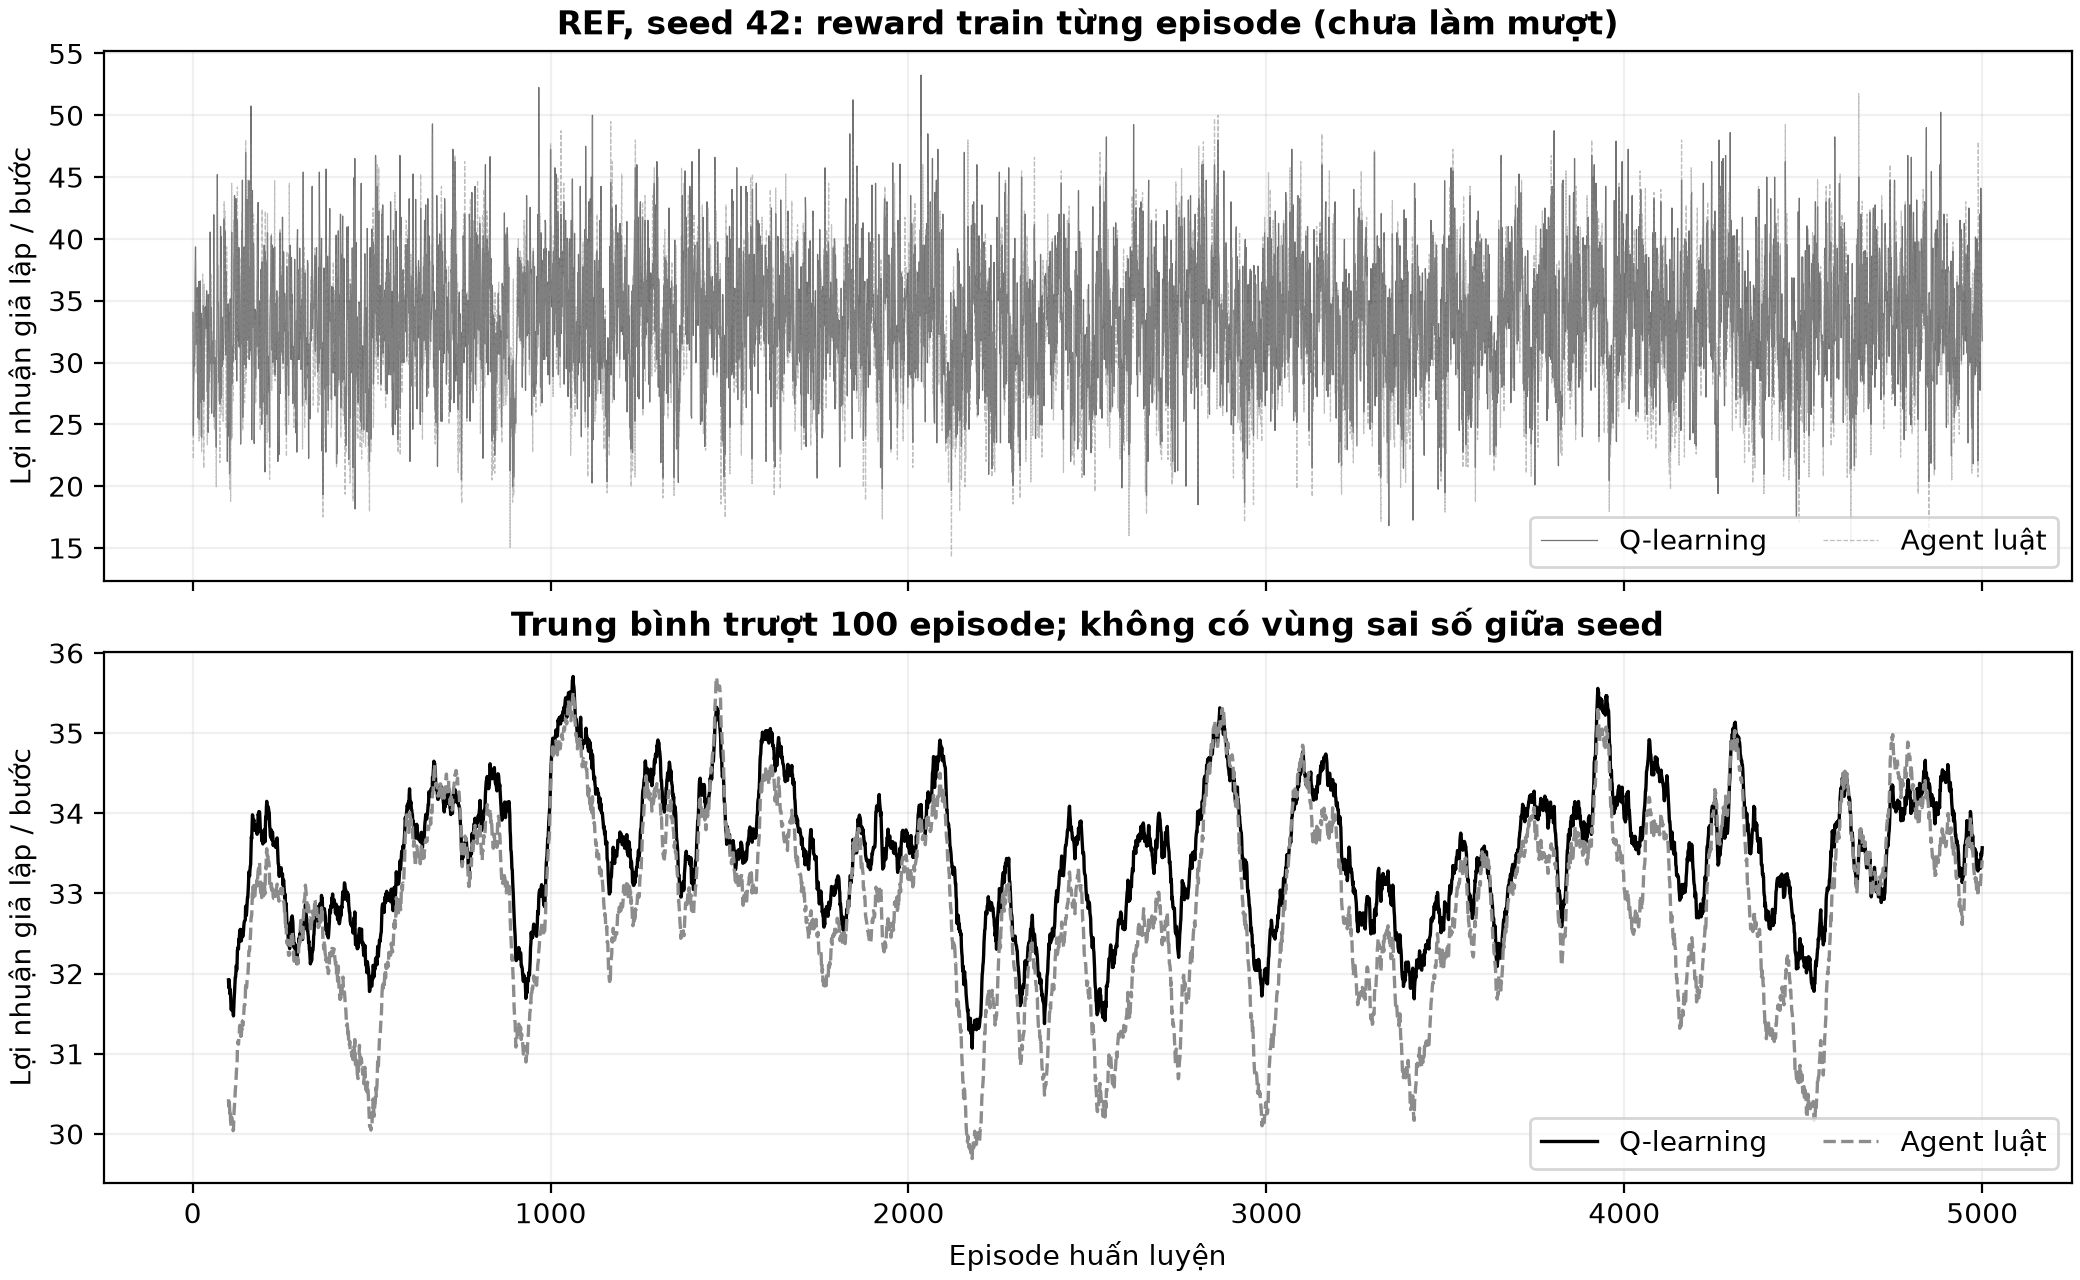

In [24]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F01')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** X là episode train, Y là reward cả episode chia 20 bước; đen liền là RL, xám đứt là rule. Panel dưới làm mượt 100 episode; chỉ có một seed, không có dải sai số giữa seed. RL tăng từ 31,92100 ở 100 episode đầu lên 33,56900 ở 100 episode cuối. Reward vẫn dao động; nhu cầu/doanh số ngẫu nhiên và policy đang học cùng ảnh hưởng đường vẽ. Làm mượt không chứng minh hội tụ hoặc ưu thế ngoài mẫu. Nguồn: D3, run REF42.

## Hình F02

Nguồn `artifacts/figures/phase03/controlled_learning_curve.png`.

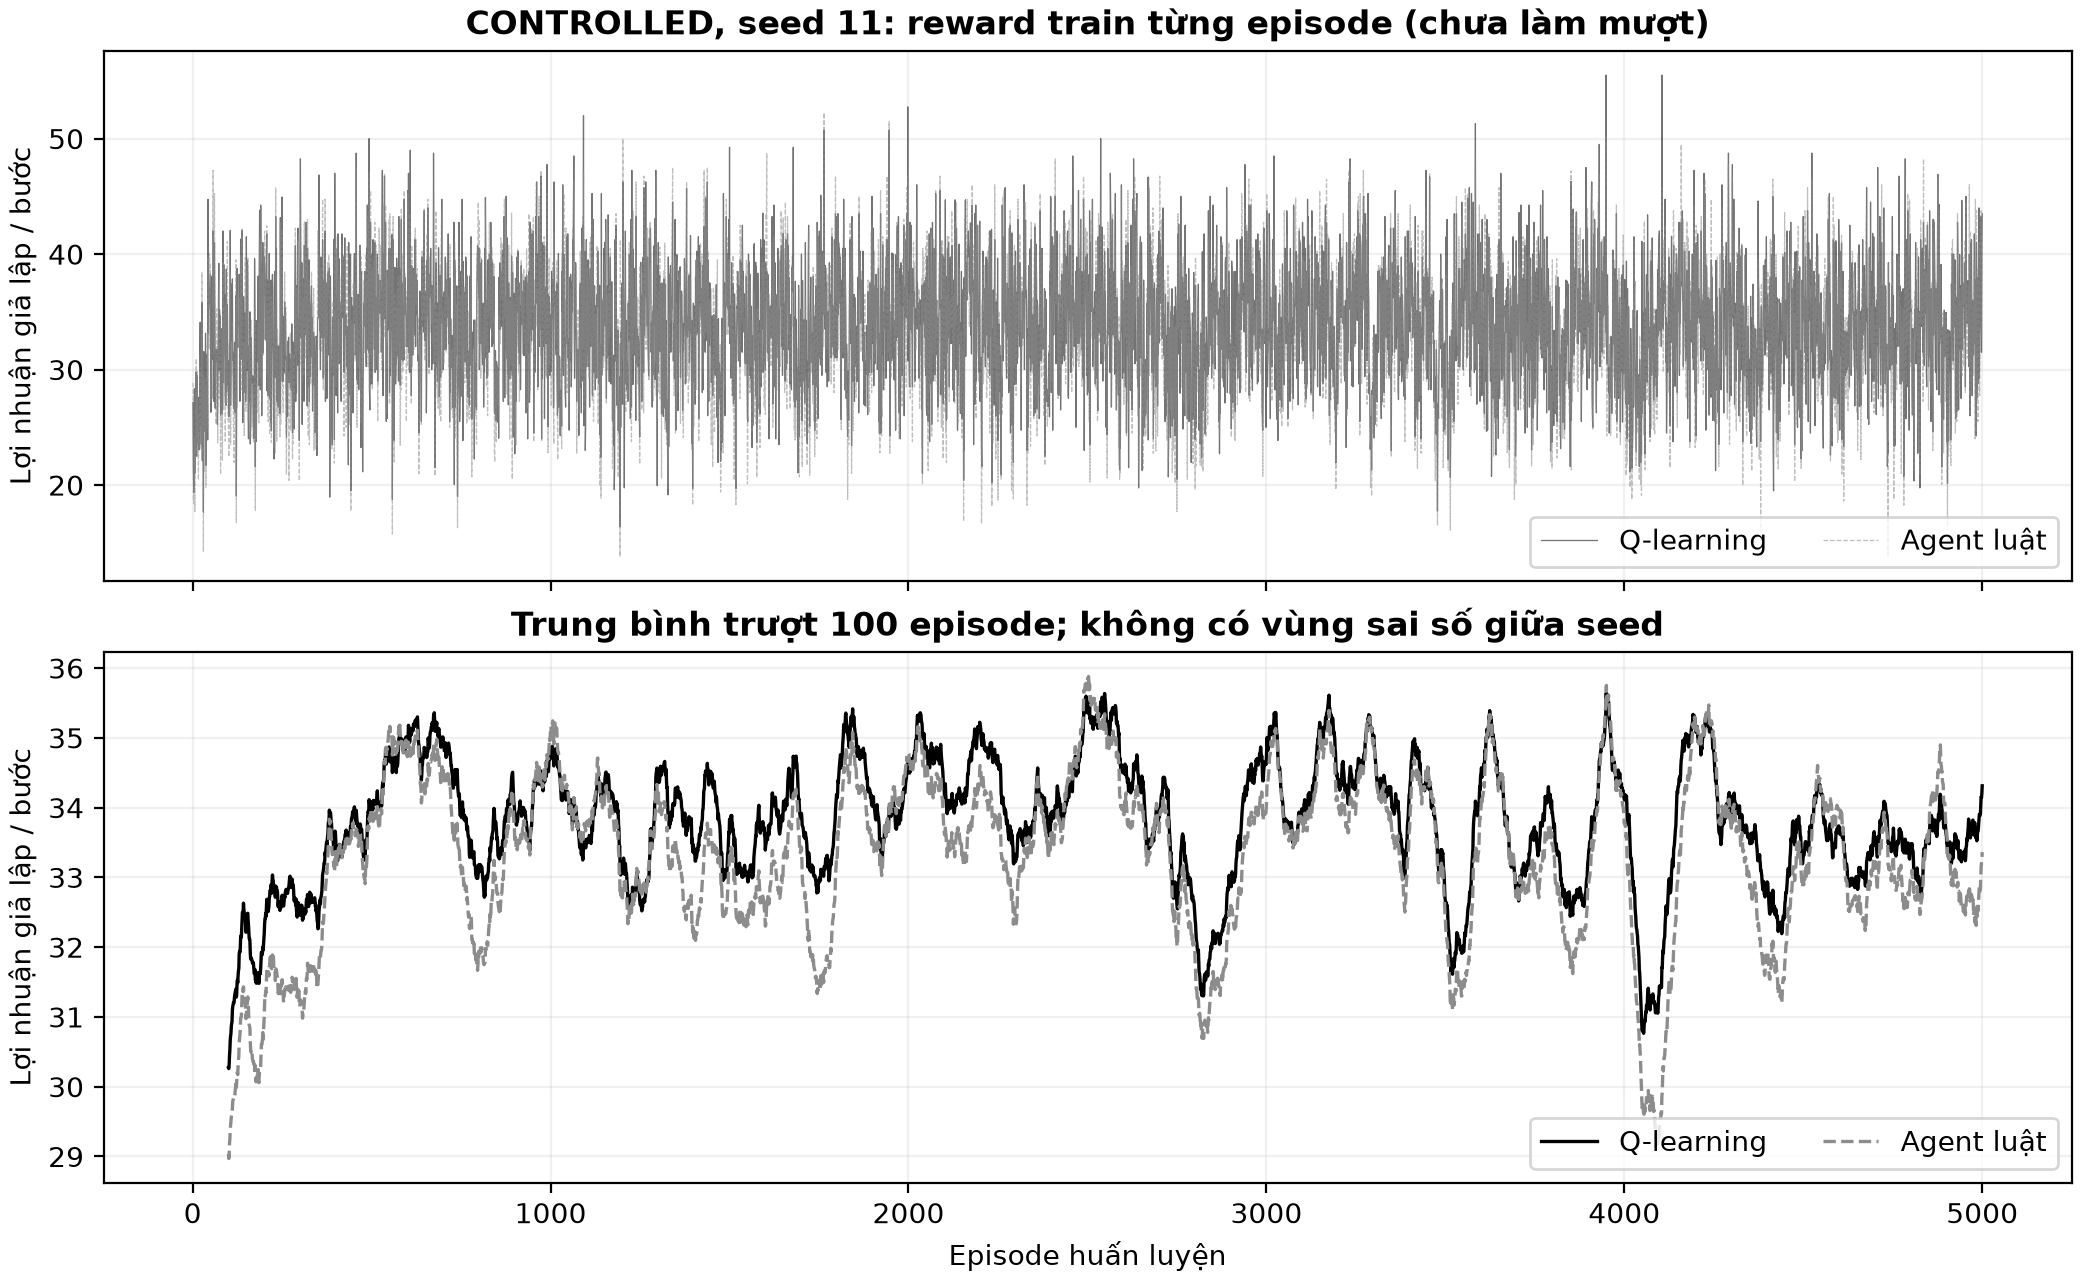

In [25]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F02')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** X là episode train, Y là profit/bước; đen RL, xám đứt rule. Panel dưới là MA 100; chỉ một seed 11, không có dải sai số giữa seed và không phải các learner độc lập. RL đầu/cuối là 30,27150/ 34,31200, rule là 29,03400/ 33,36200. Rule không học vẫn thay reward do learner và thị trường đổi. Không lấy chênh giữa F01–F02 để xếp hạng cách quản lý RNG vì cả seed cũng khác. Nguồn: D3, run CONTROLLED11.

## Hình F03

Nguồn `artifacts/figures/phase03/q_tables.png`.

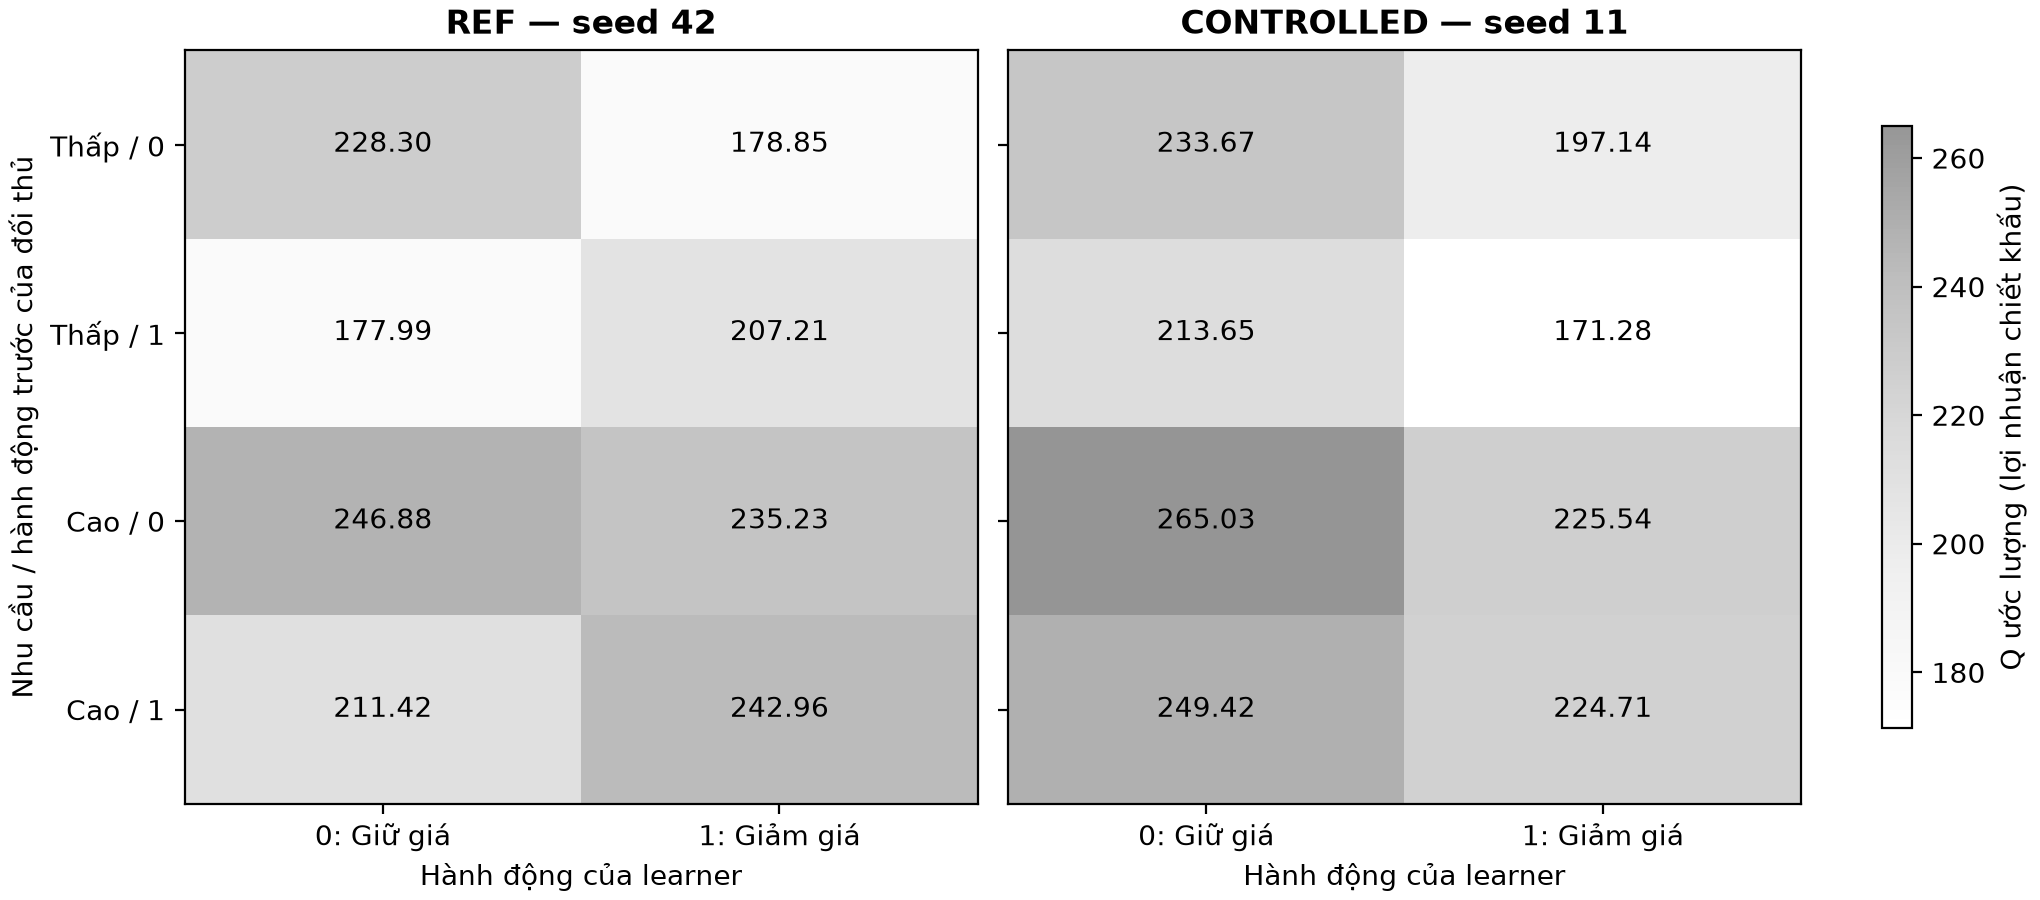

In [26]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F03')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** Hàng là bốn state nhu cầu/action trước của đối thủ; cột là hai action. Ô tối hơn có Q lớn hơn, số trong ô là Q chịu chiết khấu, không phải profit/bước. Không lấy trung bình hai track hoặc vẽ error bar. B02 cho thấy REF chọn 1 ởstate(0,1)/(1,1), trong khi CONTROLLED chọn 0 ởcảbốnstate. State ít hoặc không gặp trong policy greedy có thể không ảnh hưởng score của kịch bản hiện tại. Nguồn: D3, Q/policy cuối.

## Hình F04

Nguồn `artifacts/figures/phase03/action_counts.png`.

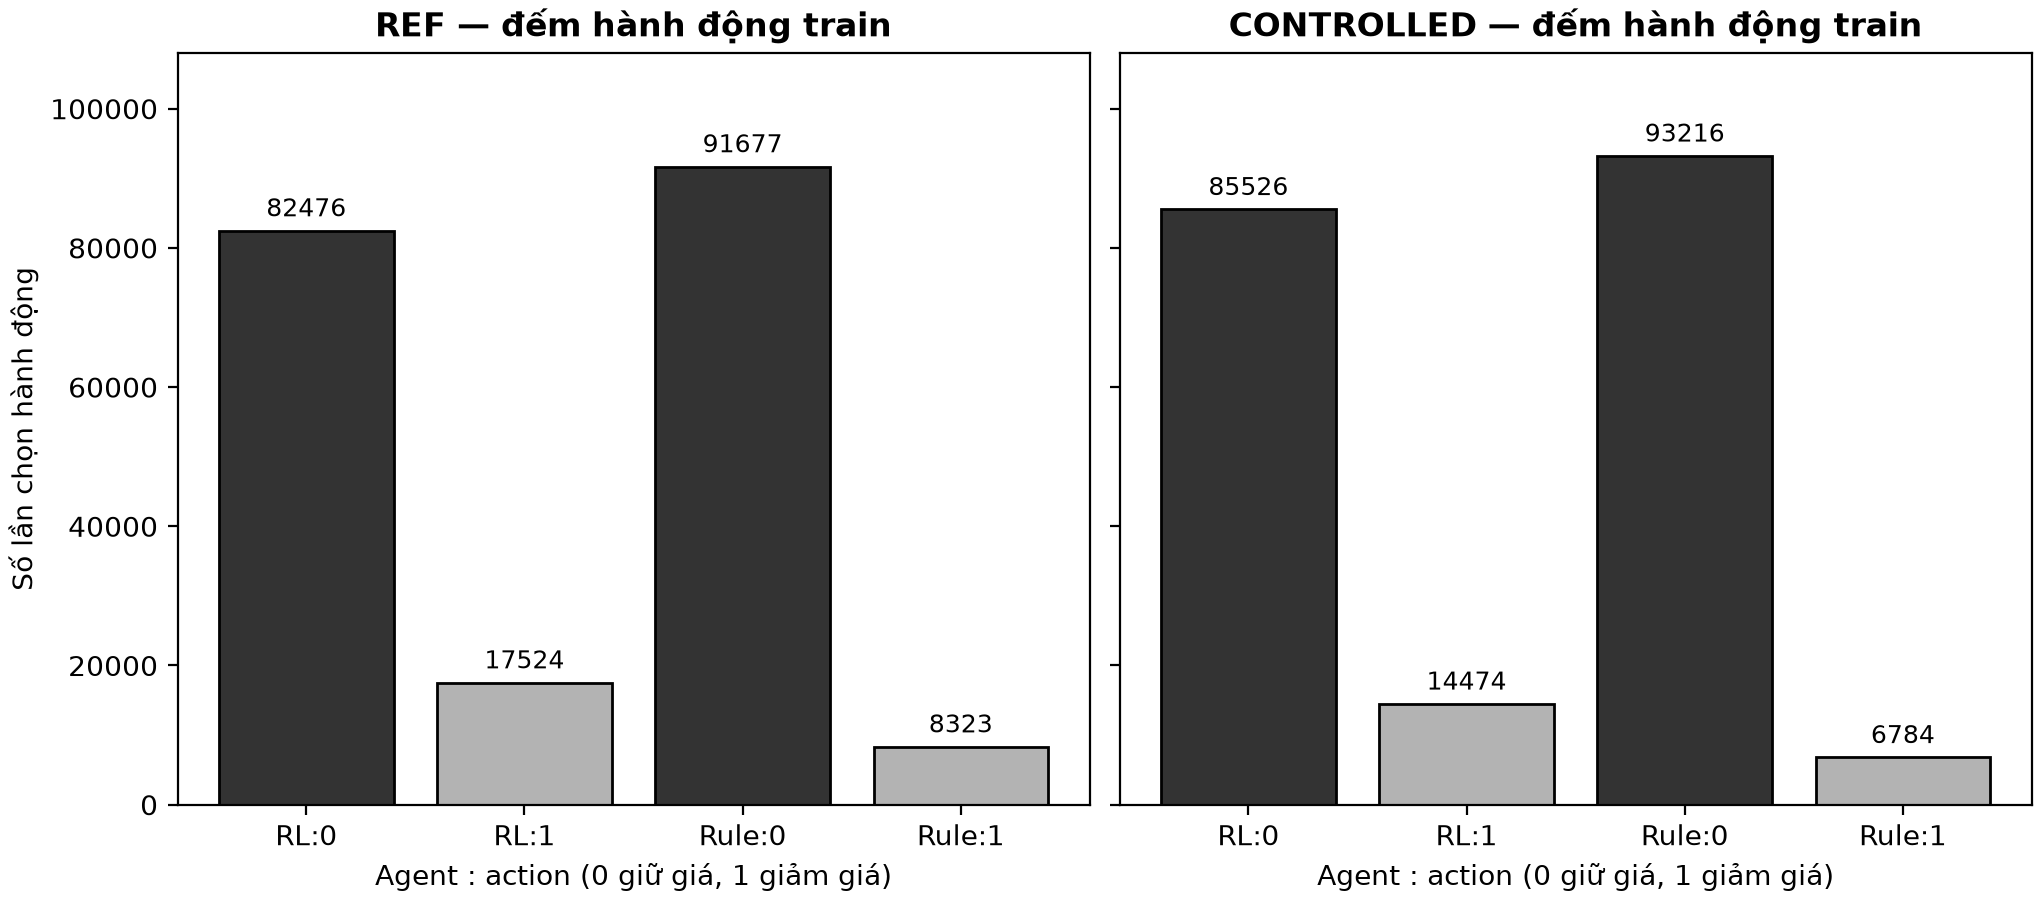

In [27]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F04')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** X là từng cặp agent/action; Y là tổng số lần chọn trên 100.000 bước/run. Cột tối giữ giá, cột sáng giảm giá; không có std vì mỗi track chỉ một seed. REF learner giảm 17524 lần, CONTROLLED giảm 14474 lần. Đây là hành vi khi còn exploration, không phải tỷ lệ epsilon hoặc tần suất của policy cuối. Giảm giá nhiều hơn không tự mang lợi nhuận cao hơn. Nguồn: D3, action_counts.

## Hình F05

Nguồn `artifacts/figures/phase04/alpha_curves.png`.

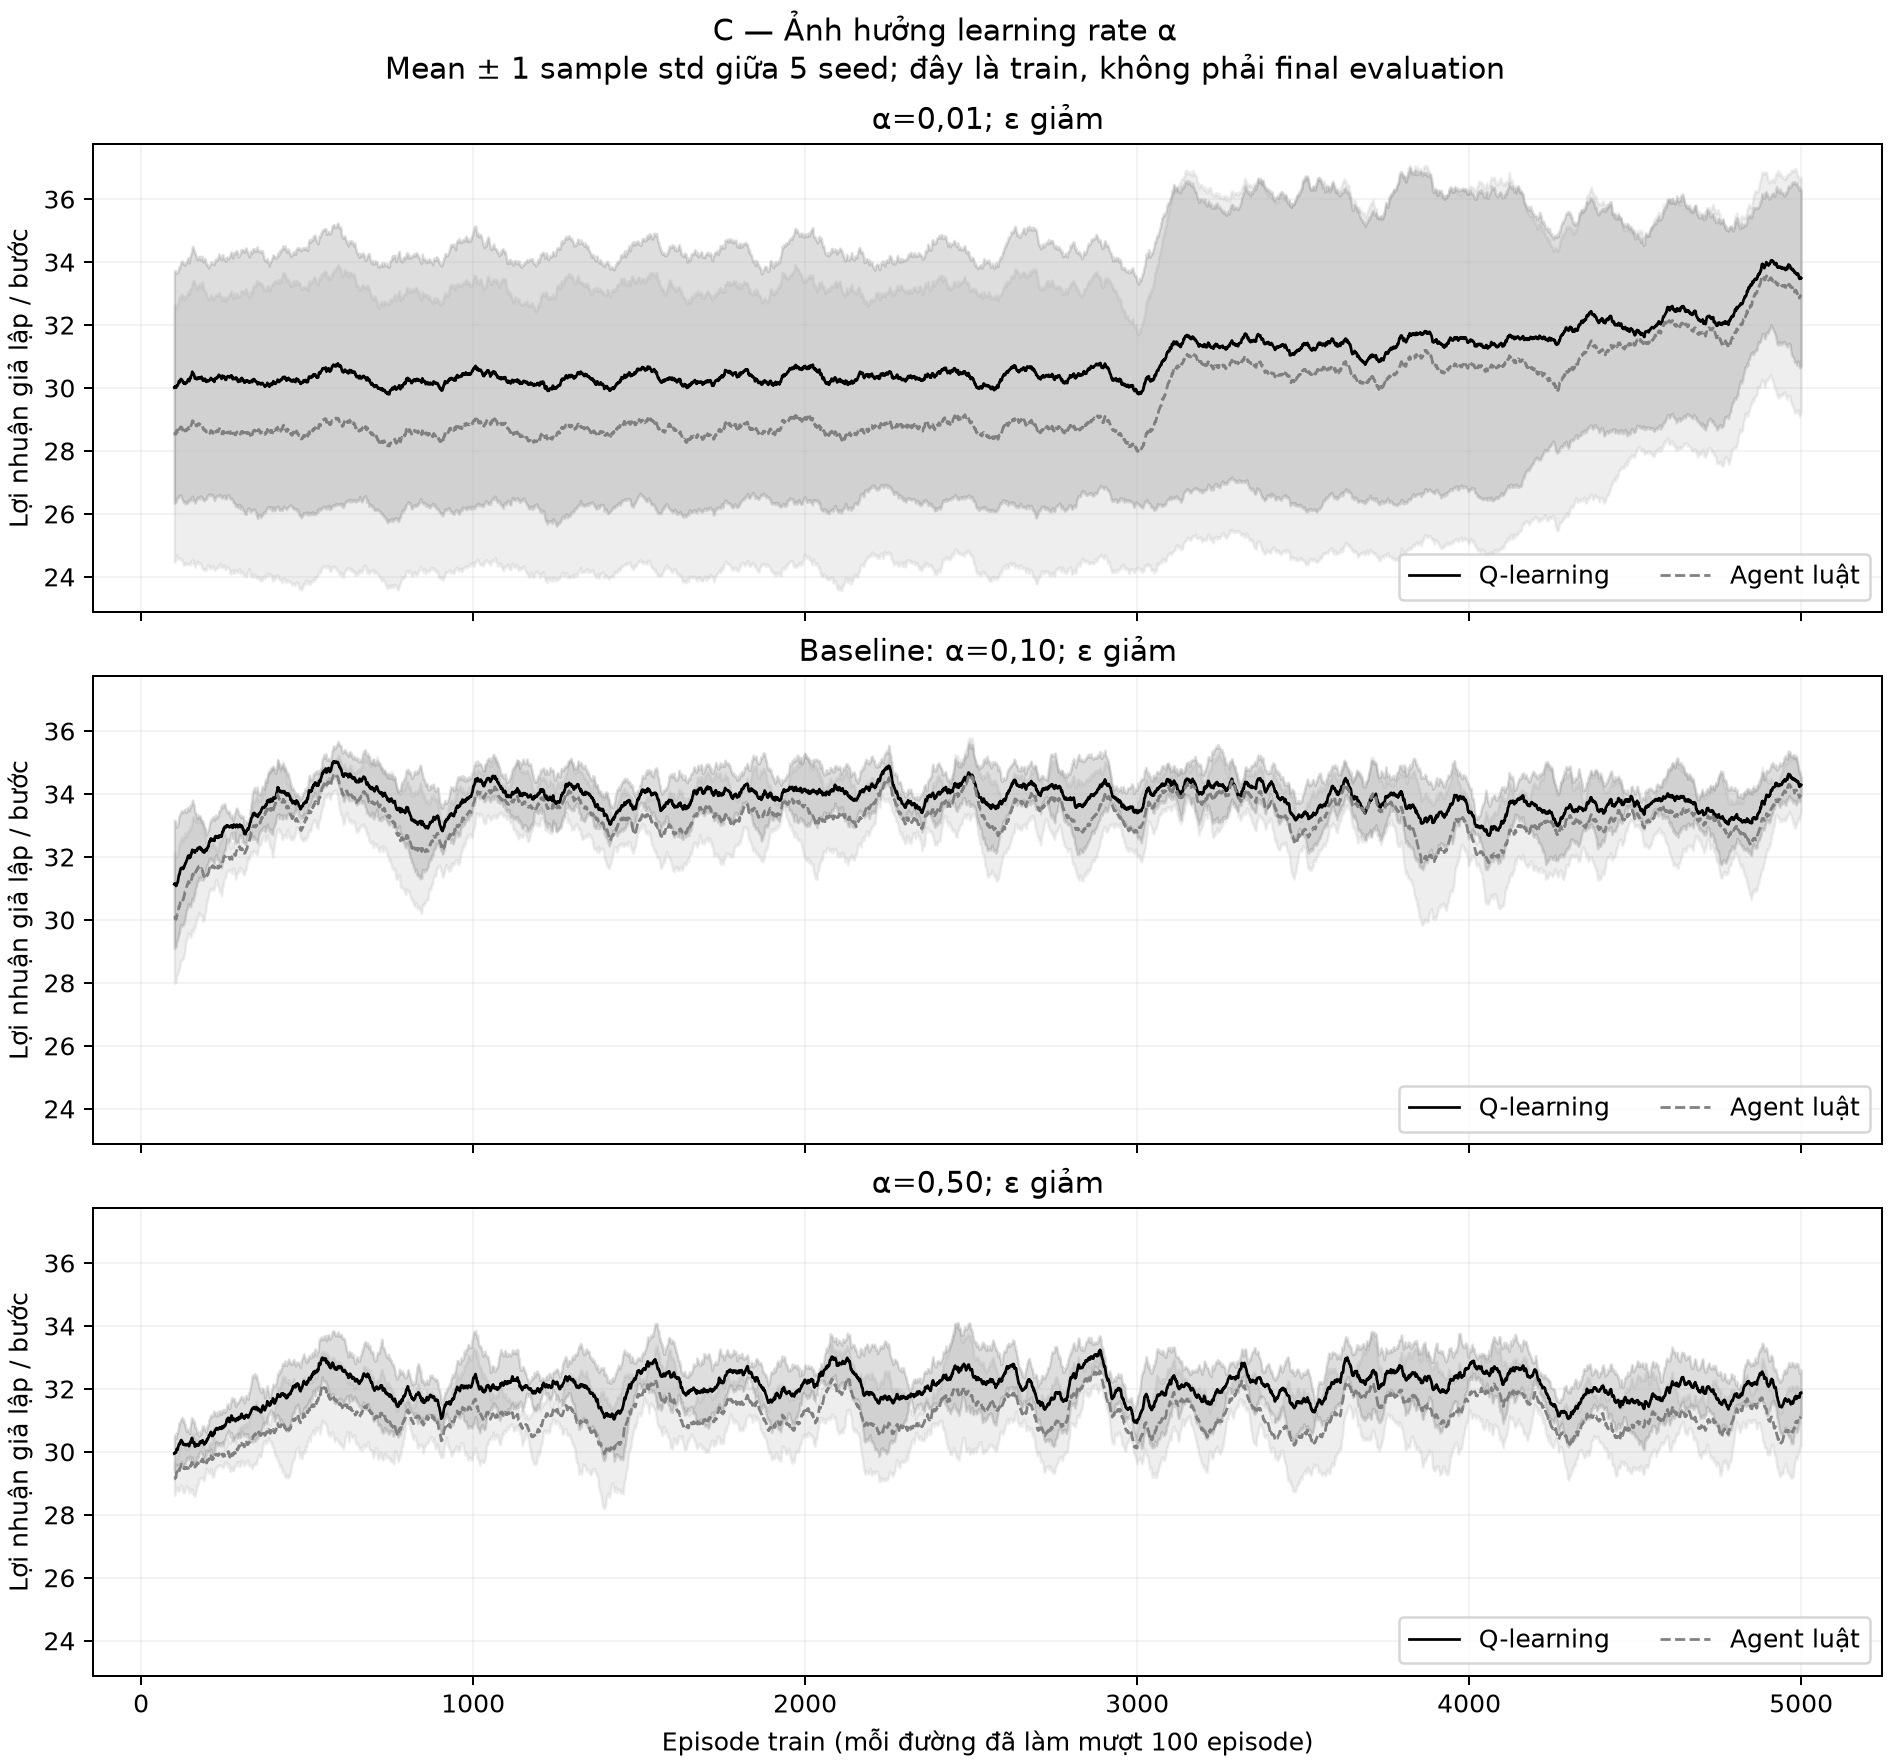

In [28]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F05')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** Mỗi panel ứng với α 0,01/0,10/0,50; X là episode, Y là profit/bước. Đen RL, xám đứt rule; MA 100 riêng từng seed trước rồi mean±sample std qua 5 seed. Cuối cửa sổ, RL lần lượt 33,49160,34,28750, 31,87860. Alpha lớn cập nhật mạnh nhưng không tạo final mean cao hơn trong mẫu này. Vùng mờ giữa seed khác với nhiễu từng bước; không dùng overlap của dải để làm kiểm định. Nguồn: D4, curves_mean_std.

## Hình F06

Nguồn `artifacts/figures/phase04/exploration_curves.png`.

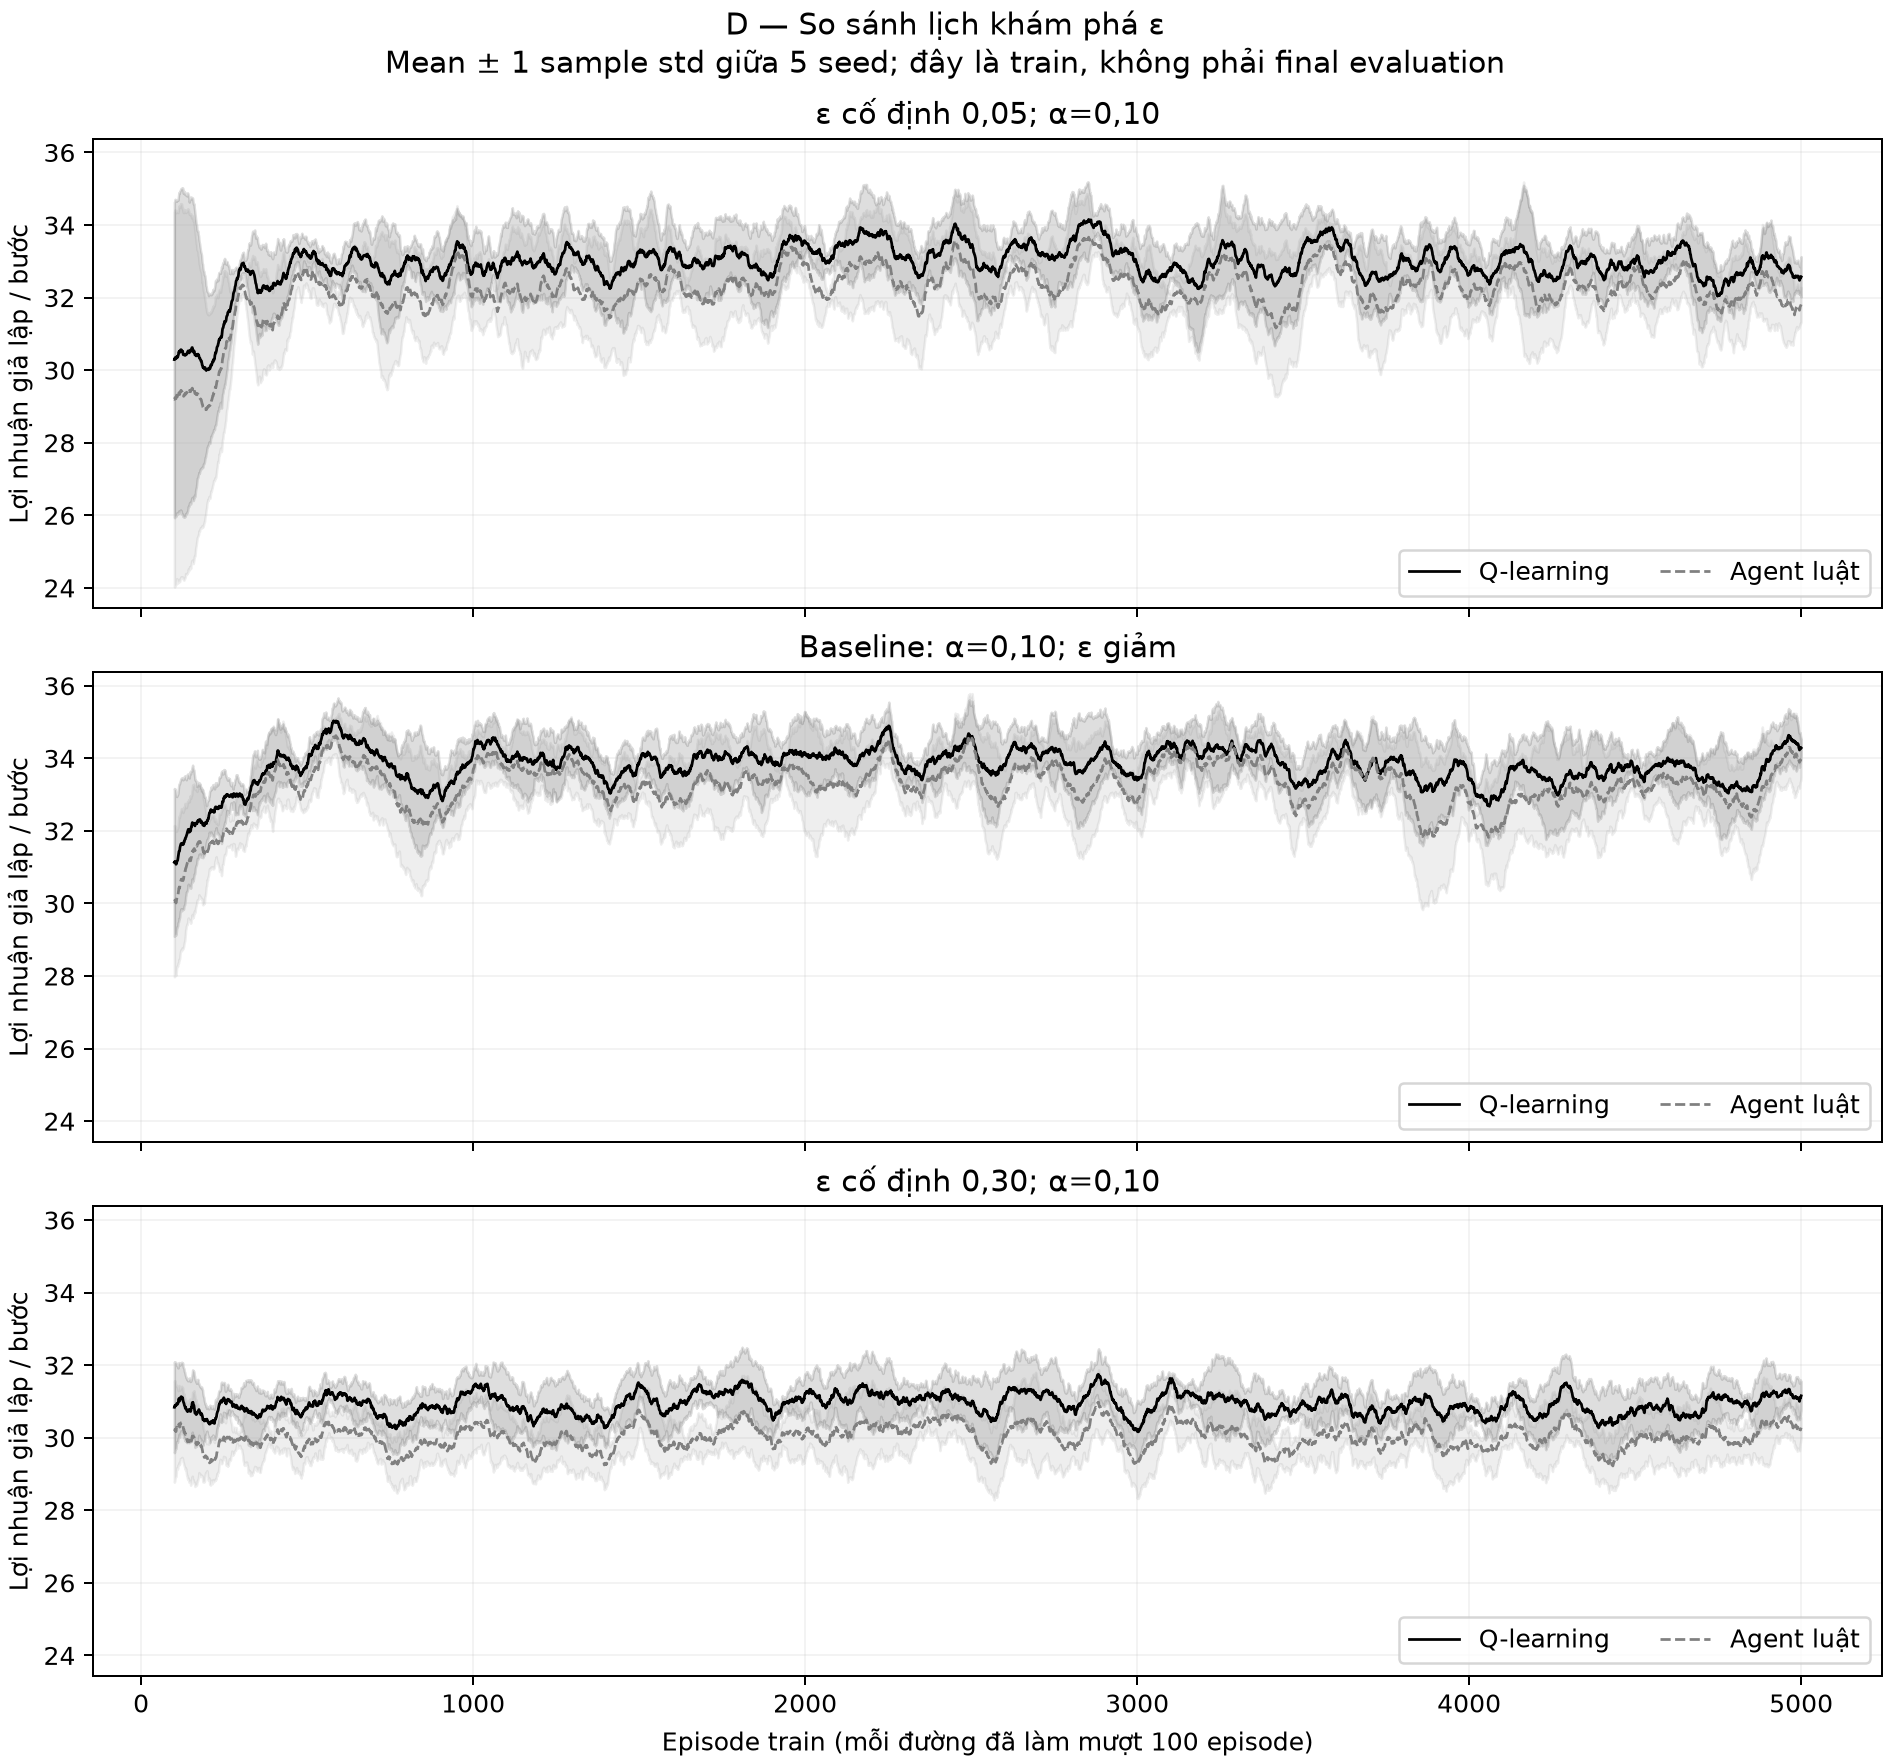

In [29]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F06')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** X là episode, Y là profit/bước; đen RL, xám đứt rule. MA 100 riêng từng seed rồi mean/std qua 5 seed như F05; chỉ thay lịch khám phá. RL ở cửa sổ cuối của epsilon 0,05, baseline giảm, epsilon 0,30 lần lượt 32,57480, 34,28750, 31,15510. Khám phá cao có thể làm reward train thấp vì tiếp tục thử action, nhưng không kết luận chỉ từ train rằng policy cuối kém hơn. Nguồn: D4.

## Hình F07

Nguồn `artifacts/figures/phase04/epsilon_schedules.png`.

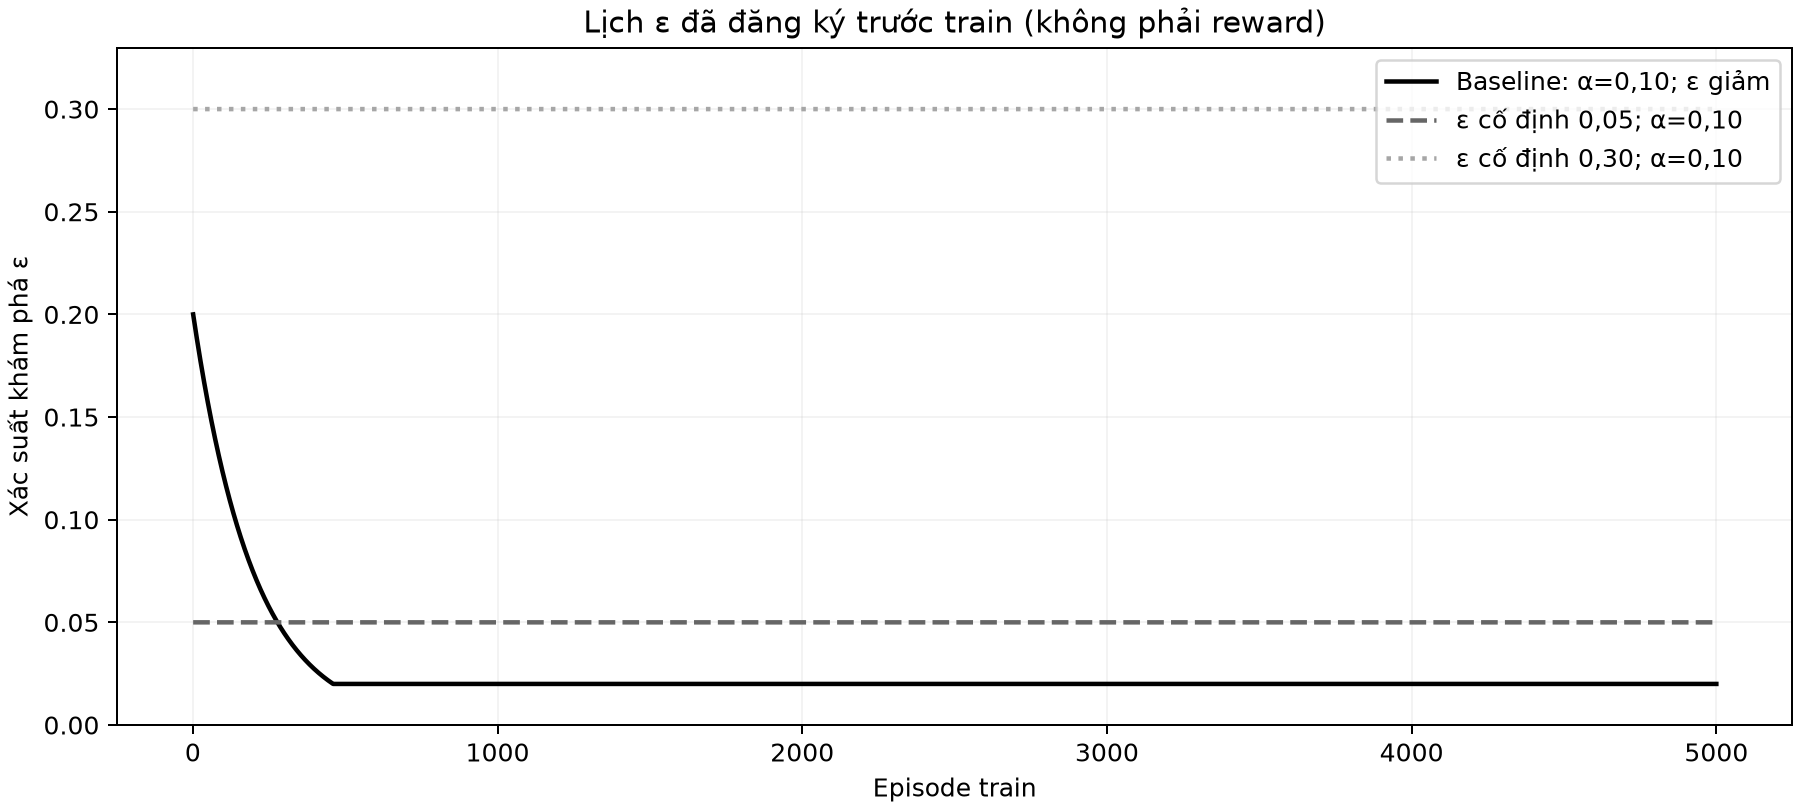

In [30]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F07')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** X là episode, Y là xác suất khám phá, không có đơn vị reward. Đường đen giảm 0,20 → 0,02; hai đường còn lại giữ 0,05/0,30. Đây là cấu hình chung cho cả 5 seed, không phải số đo ngẫu nhiên nên không có dải std. Epsilon chỉ là xác suất chọn action ngẫu nhiên; tỷ lệ giảm giá còn phụ thuộc action được chọn khi khám phá và policy khi khai thác. Nguồn: D2,D4, epsilon_schedules.

## Hình F08

Nguồn `artifacts/figures/phase04/train_summary.png`.

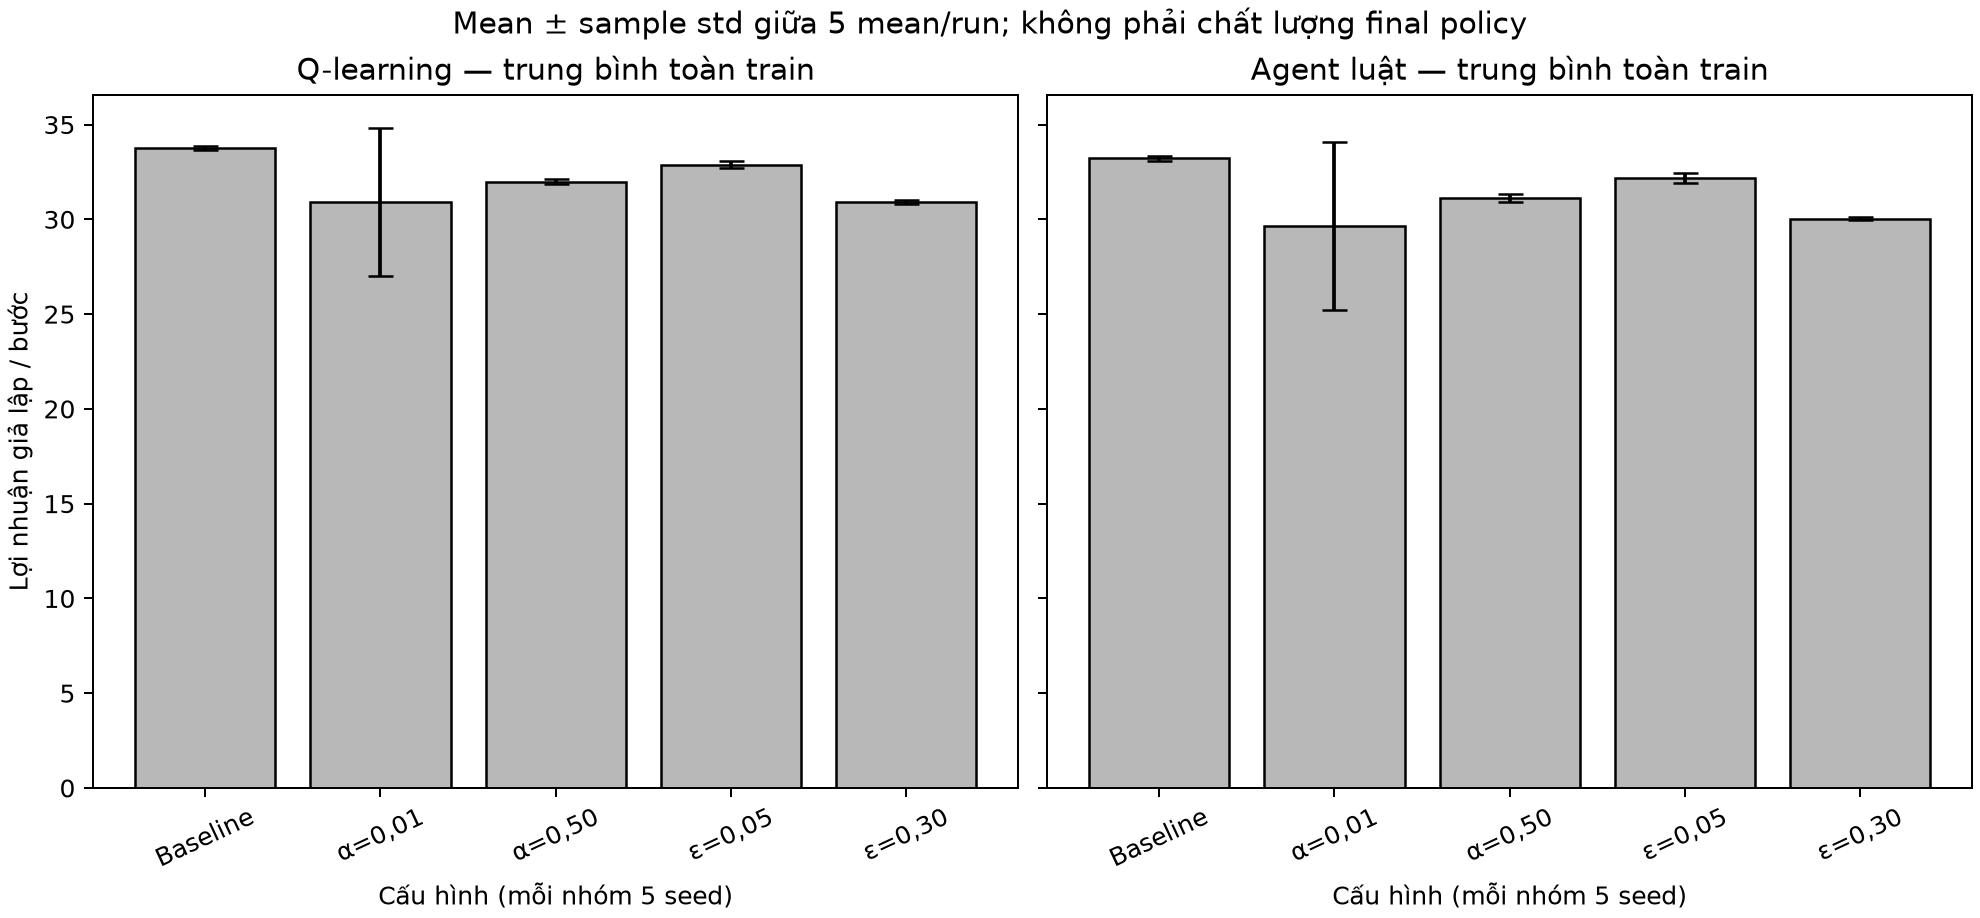

In [31]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F08')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** Hai panel tách RL và rule; X là cấu hình, Y là mean profit/bước trên 100.000 bước/run. Cột là mean 5 run, whisker là sample std của 5 mean/run. Baseline RL 33,76528±0,09989; alpha 0,01 30,91717±3,91720. Dải của alpha 0,01 lớn hơn nhiều giữa seed; không bỏ seed bất lợi. Đó là train score, chưa phải chất lượng cuối đo trước cùng opponent/tape. Nguồn: D4.

## Hình F09

Nguồn `artifacts/figures/phase05/final_profit.png`.

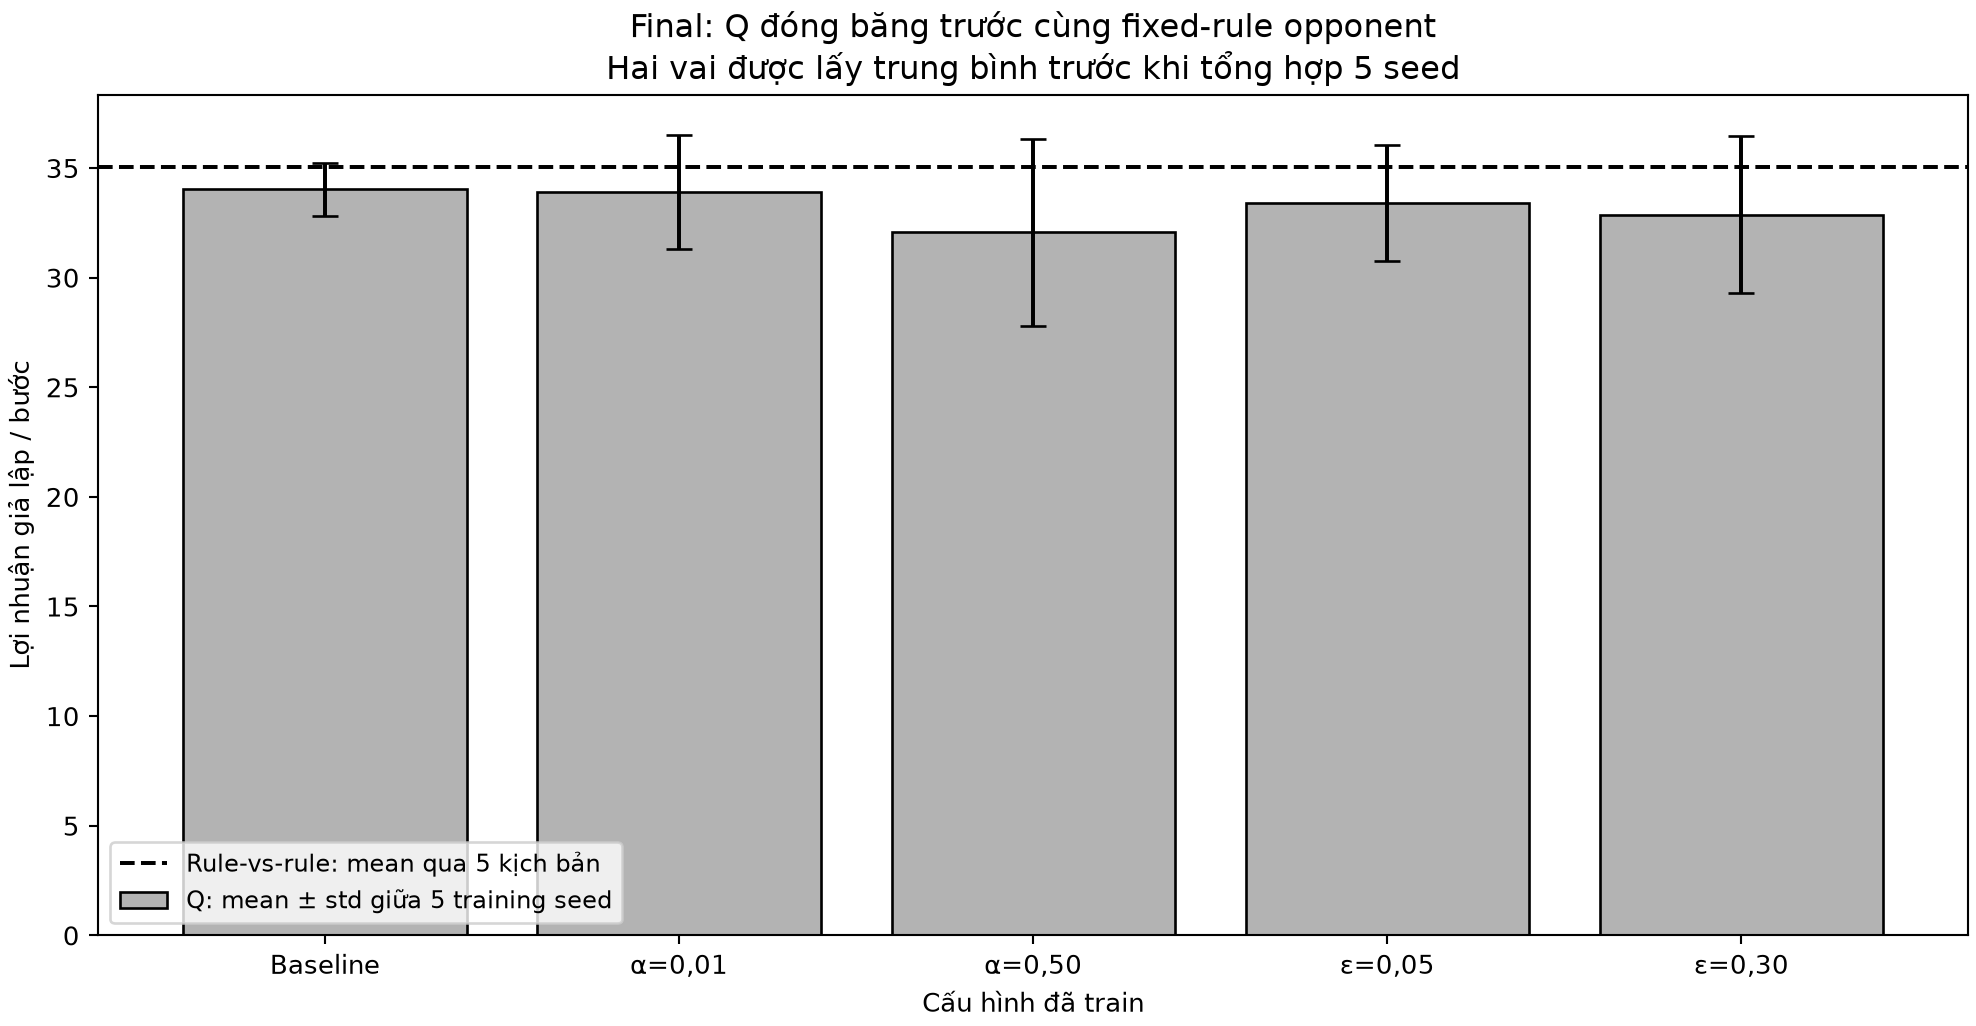

In [32]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F09')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** X là năm cấu hình,Y là profit/bước; cột mean, whisker là std qua 5 training seed sau gộp vai. Đường đứt là mean Rule-vs-rule qua 5 scenario panel, không phải rule đã train. Baseline 34,02786 cao nhất trong năm mean quan sát, alpha 0,50 là 32,06337; không từ đó chọn lại cấu hình hoặc khẳng định ưu thế thống kê/phổ quát. Nguồn: D5, config_summary.

## Hình F10

Nguồn `artifacts/figures/phase05/paired_and_match.png`.

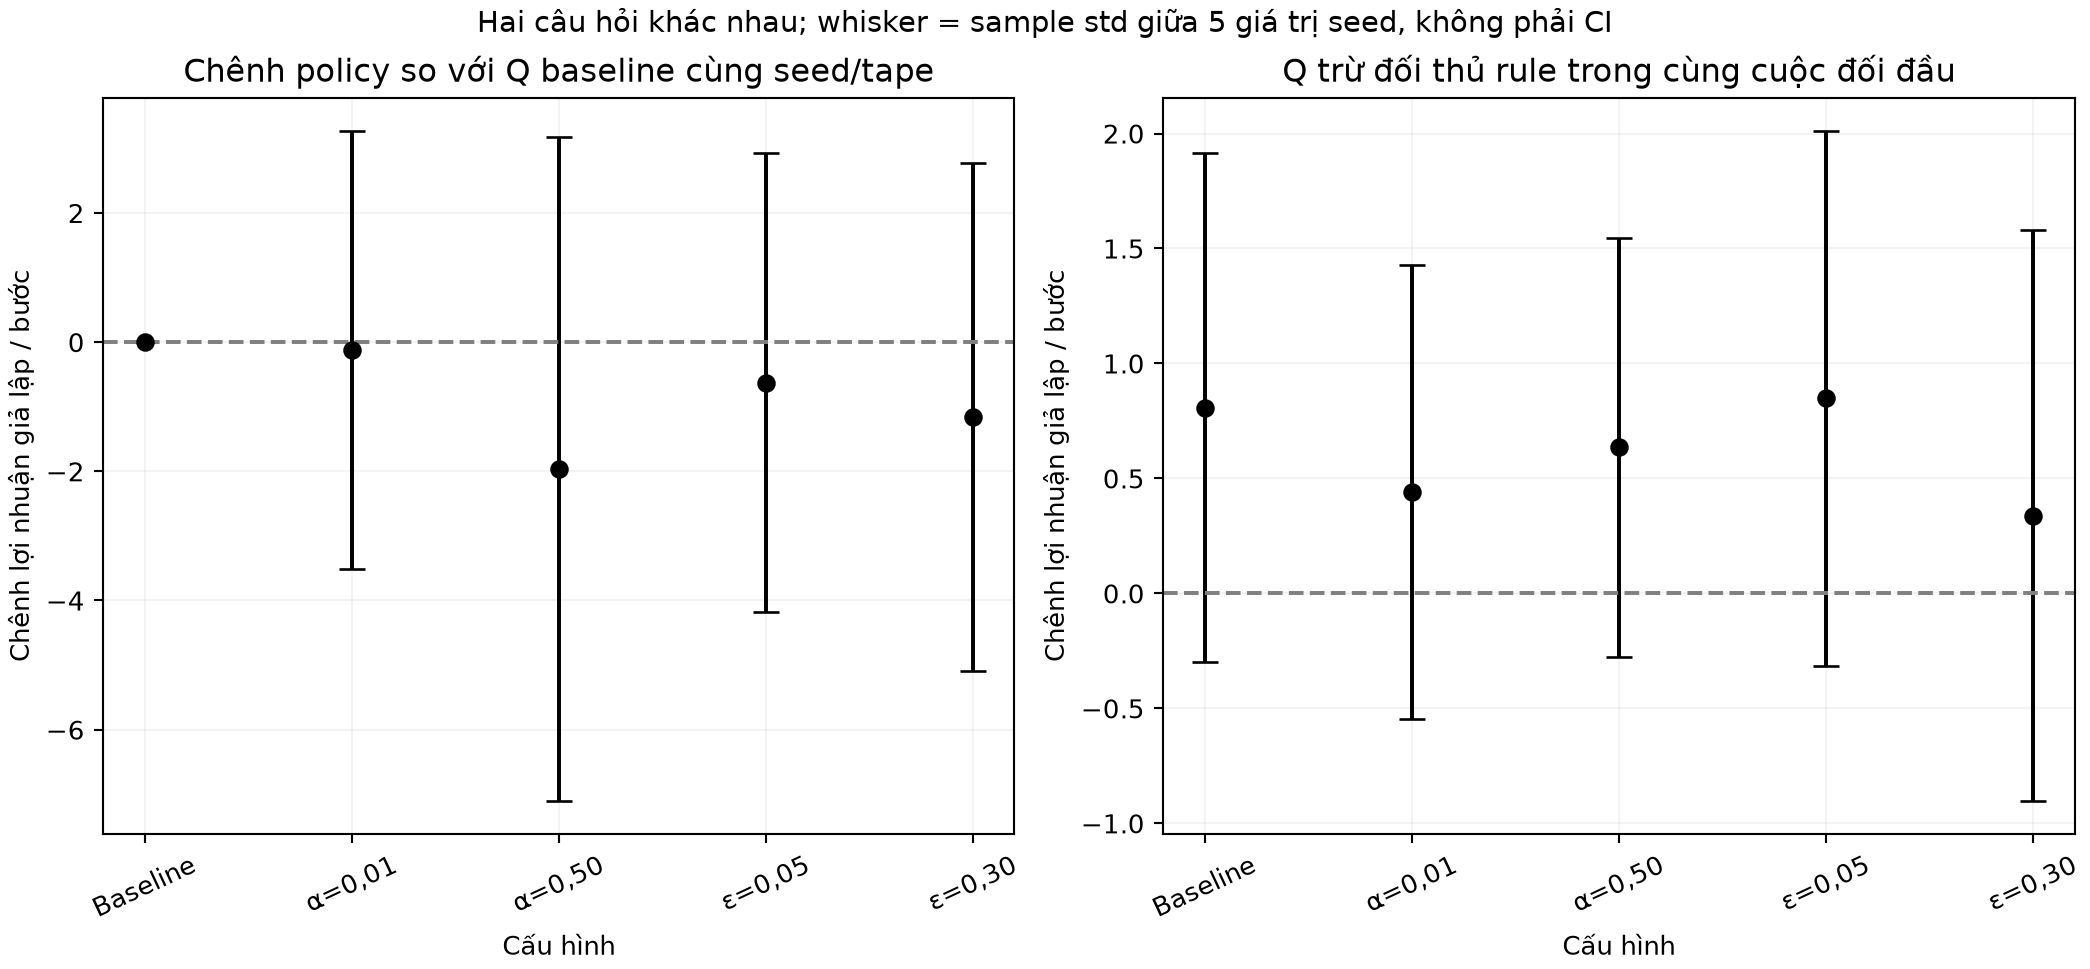

In [33]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F10')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** Hai panel cùng X là cấu hình,Y là chênh profit/bước; chấm mean, whisker sample std qua 5 delta seed, đường 0 là không chênh. **Panel trái** là Q cấu hình trừ Q baseline cùng seed/tape; **panel phải** là Q trừ rule trong chính trận đó. Alpha 0,50 có delta so baseline -1,96449, nhưng delta trong trận 0,63457. Không dùng panel phải để tuyên bố Q tốt hơn policy rule trước cùng opponent. Nguồn: D5, paired_comparison.

## Hình F11

Nguồn `artifacts/figures/phase05/train_vs_final.png`.

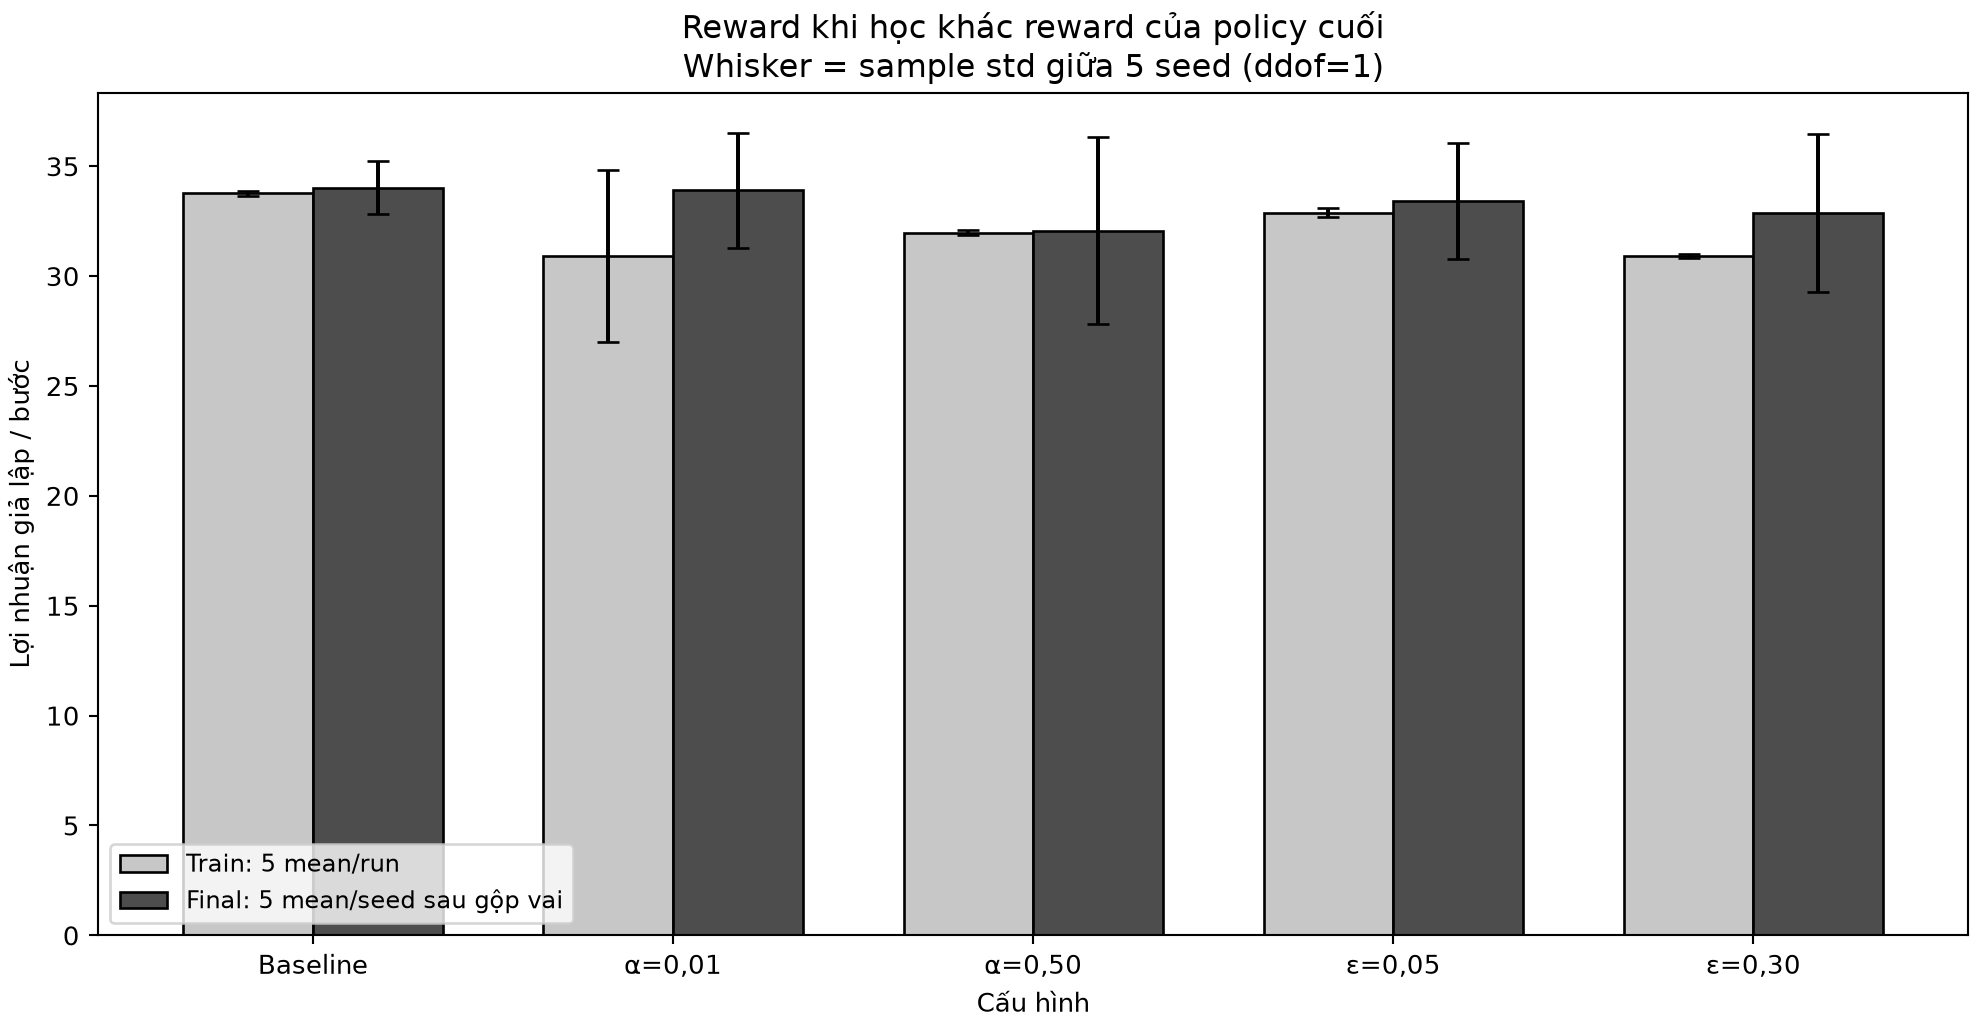

In [34]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F11')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** X là cấu hình,Y là profit/bước; cột sáng là toàn quá trình học, cột tối là policy cuối đóng băng trên scenario riêng, whisker đều giữa 5 seed. Alpha 0,01 train mean 30,91717 còn finalmean 33,90382. Chênh lệch gồm cả policy thay đổi, exploration và tập tình huống; không quy toàn bộ cho việc tắt epsilon hoặc gọi score tăng là hội tụ. Nguồn: D4,D5.

## Hình F12

Nguồn `artifacts/figures/phase05/discount_rates.png`.

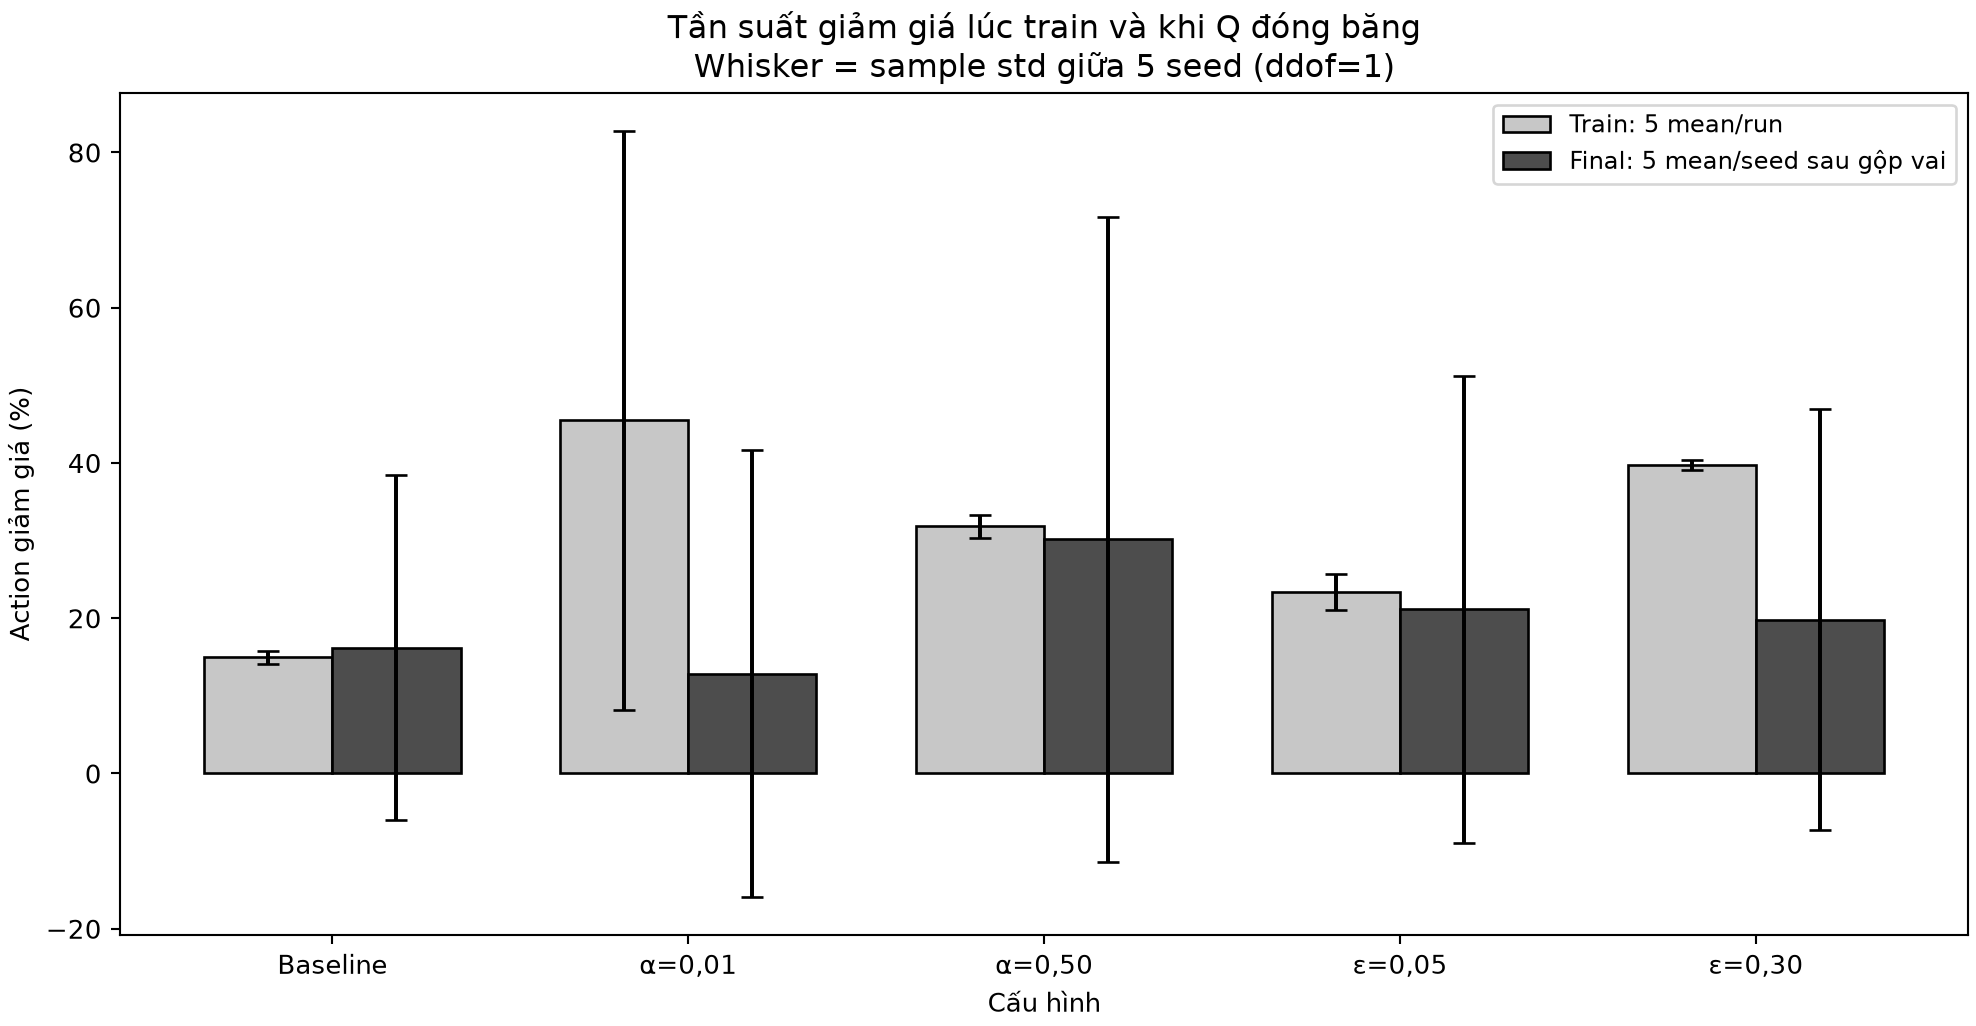

In [35]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F12')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** X là cấu hình,Y là tỷ lệ giảm giá(%); cột sáng train 100.000 bước/run, tối final 20.000 bước/seed gộp hai vai. Whisker là sample std giữa 5 seed, đơn vị điểm%. Final baseline 16,212%, alpha 0,50 30,186%. Tỷ lệ không bằng epsilon. Whisker mean±std có thể xuống dưới 0 khi độ phân tán lớn; từng tỷ lệ quan sát vẫn 0–100%, whisker không phải khoảng xác suất/CI. Nguồn: D4,D5.

## Hình F13

Nguồn `artifacts/figures/phase06/gold_calibration.png`.

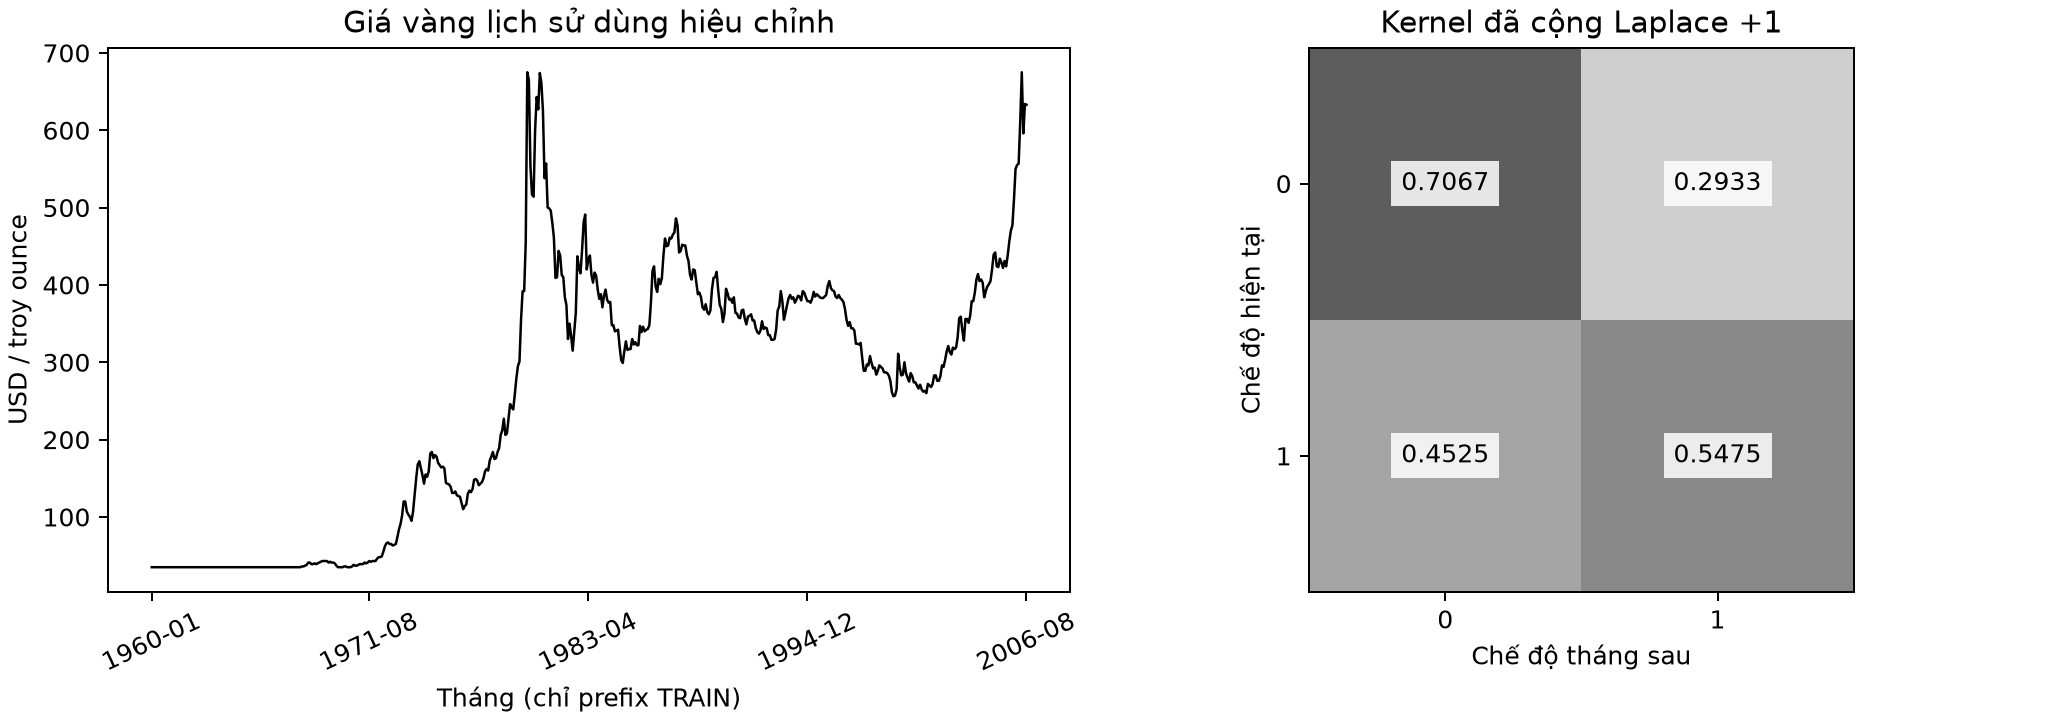

In [36]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F13')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** Trái: X là tháng, Y là USD/troy ounce; đường đen là 560 giá tháng trong prefix TRAIN, 01/1960–08/2006. Phải: hàng là regime hiện tại, cột là regime tháng sau, số trong ô là xác suất sau cộng Laplace 1. Regime 1 là giá tăng; regime 0 gồm giảm hoặc giữ nguyên. P 00=0,706745, P 11=0,547511, khác kernel persistent giữ chế độ với xác suất 0,9. Đây là hướng biến động **giá**, không phải nhu cầu vàng thực đo; không diễn giải thành quan hệ nhân quả hay backtest đầu tư. Nguồn: S7,D6, Gold TRAIN prefix/kernel.

## Hình F14

Nguồn `artifacts/figures/phase06/two_learner_training.png`.

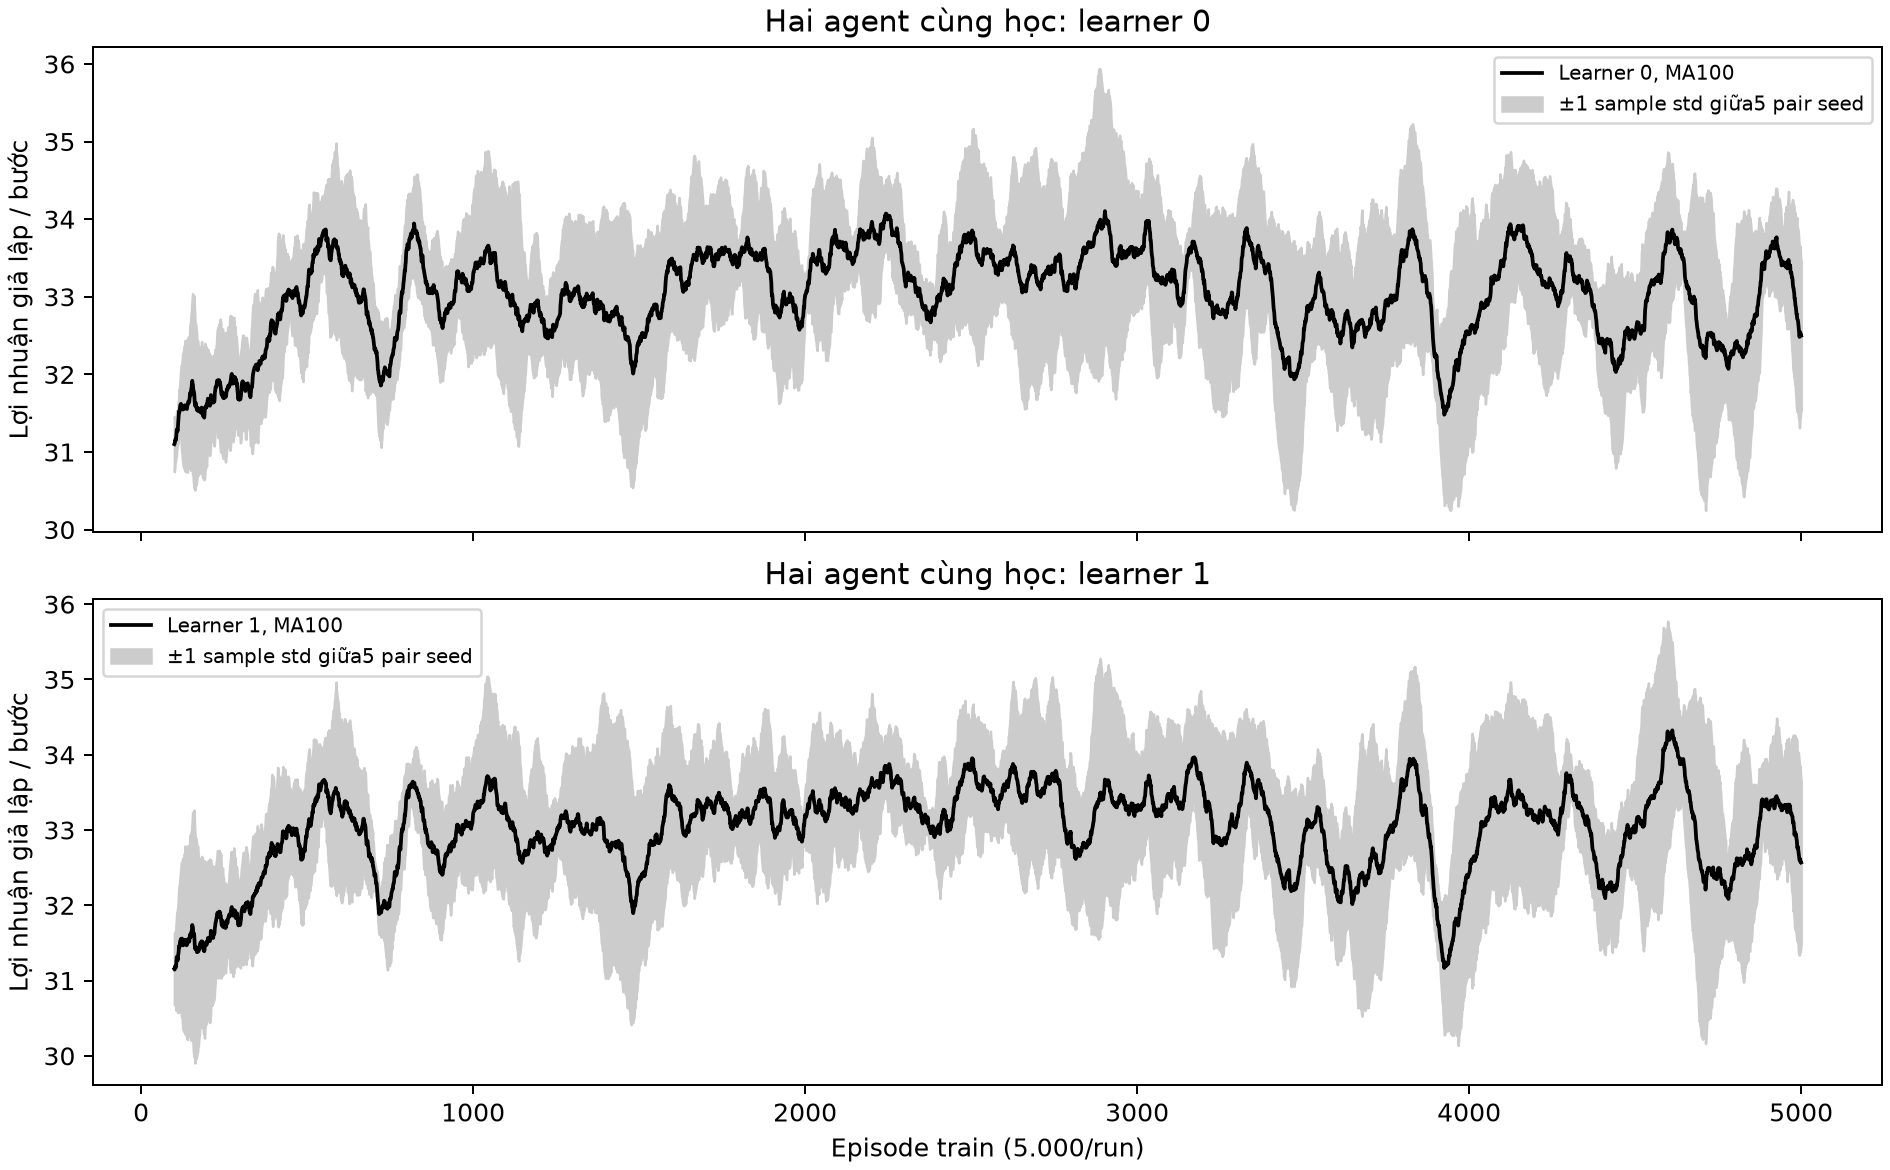

In [37]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F14')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** Hai panel tách learner 0/1; X là episode train, Y là profit/bước. Đường đen là mean của MA 100 riêng từng seed; dải xám là ±sample std qua năm pair seed. Hai đường vẫn dao động; mean train của learner 0/1 là 32,99454/ 32,98117, không tăng đều đến cuối. Đây là quá trình cả hai policy đang đổi; vùng mờ còn chứa khác biệt kinh nghiệm giữa seed. Không từ đó quy riêng biến động cho non-stationarity hoặc kết luận hội tụ. Nguồn: D6, pair_train_curves.

## Hình F15

Nguồn `artifacts/figures/phase06/checkpoint_drift.png`.

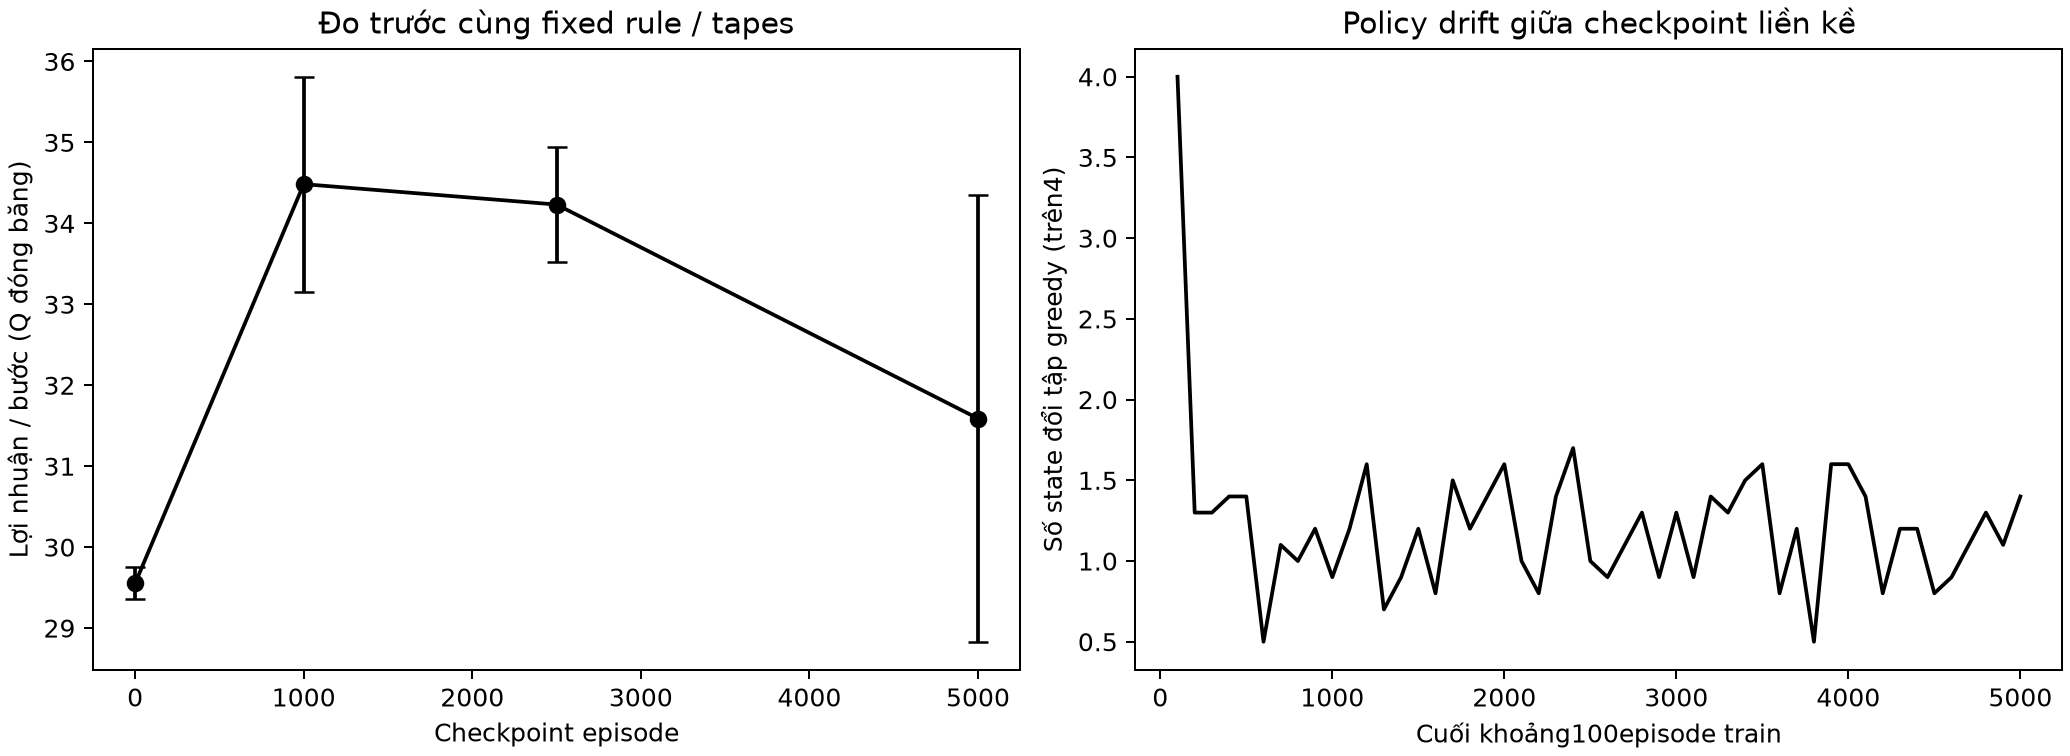

In [38]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F15')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** Trái: X là checkpoint, Y là profit/bước khi Q đóng băng trước fixed rule; chấm mean, whisker là std sau gộp vai/learner trong pair, n 5 pair seed. Mean ở 1.000 episode là 34,48443, ở 5.000 là 31,58872. Phải: X là cuối mỗi khoảng 100 episode, Y là số state đổi tập greedy trên bốn state, lấy mean qua 10 learner thuộc 5 pair. Có 612 state-change trên 500 learner-interval; không phải số lần đổi action trong timestep. Drift ở state ít gặp có thể không đổi return; không chọn checkpoint 1.000 làm kết quả cuối chỉ vì mean cao hơn. Nguồn: D6.

## Hình F16

Nguồn `artifacts/figures/phase06/variant_robustness.png`.

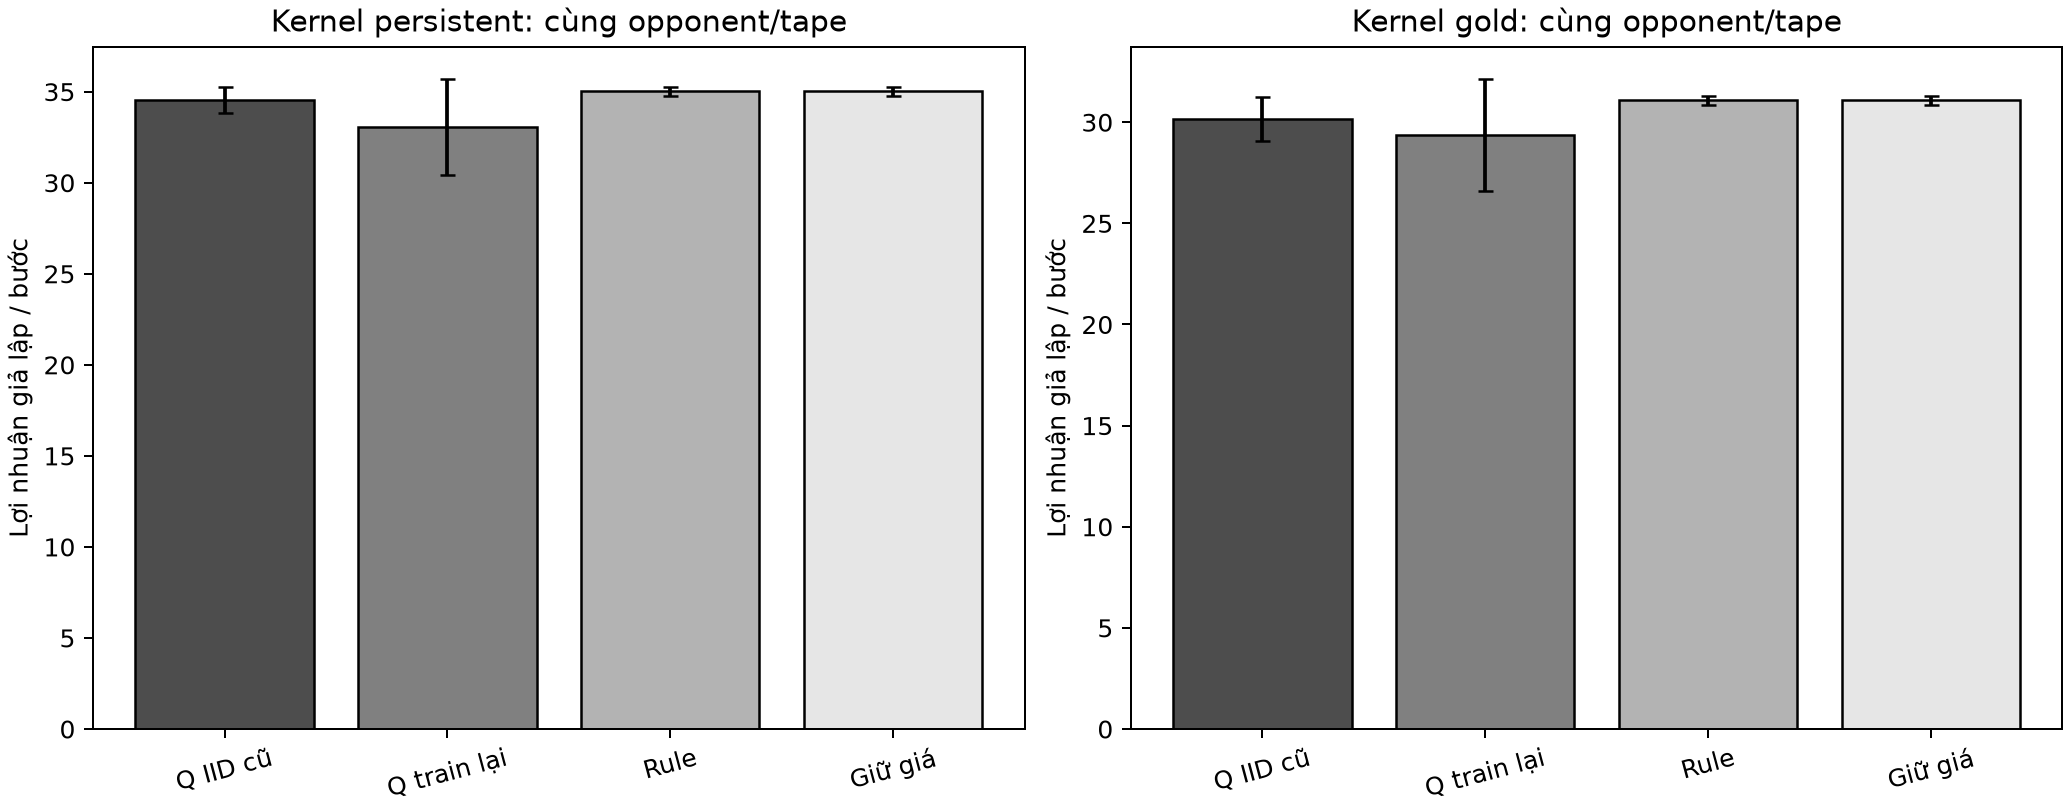

In [39]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F16')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** Mỗi panel là một kernel; X gồm Q IID cũ, Q train lại, rule và no-discount; Y là profit/bước. Cột mean, whisker là std sau gộp hai vai. Delta train lại trừ Q IID cũ là-1,48087±2,70026 ởpersistent, -0,80510±3,54276 ởGold. Rule-vs-rule và no-discount trùng hành vi giữ giá từ lịch sử reset 0, nên không coi hai cột đó là hai chuẩn hành vi độc lập. Không so raw profit xuyên kernel như cùng phân phối. Nguồn: D6, variant_seed/variant_summary/variant_deltas.

## Hình F17

Nguồn `artifacts/figures/phase07/augmented_training.png`.

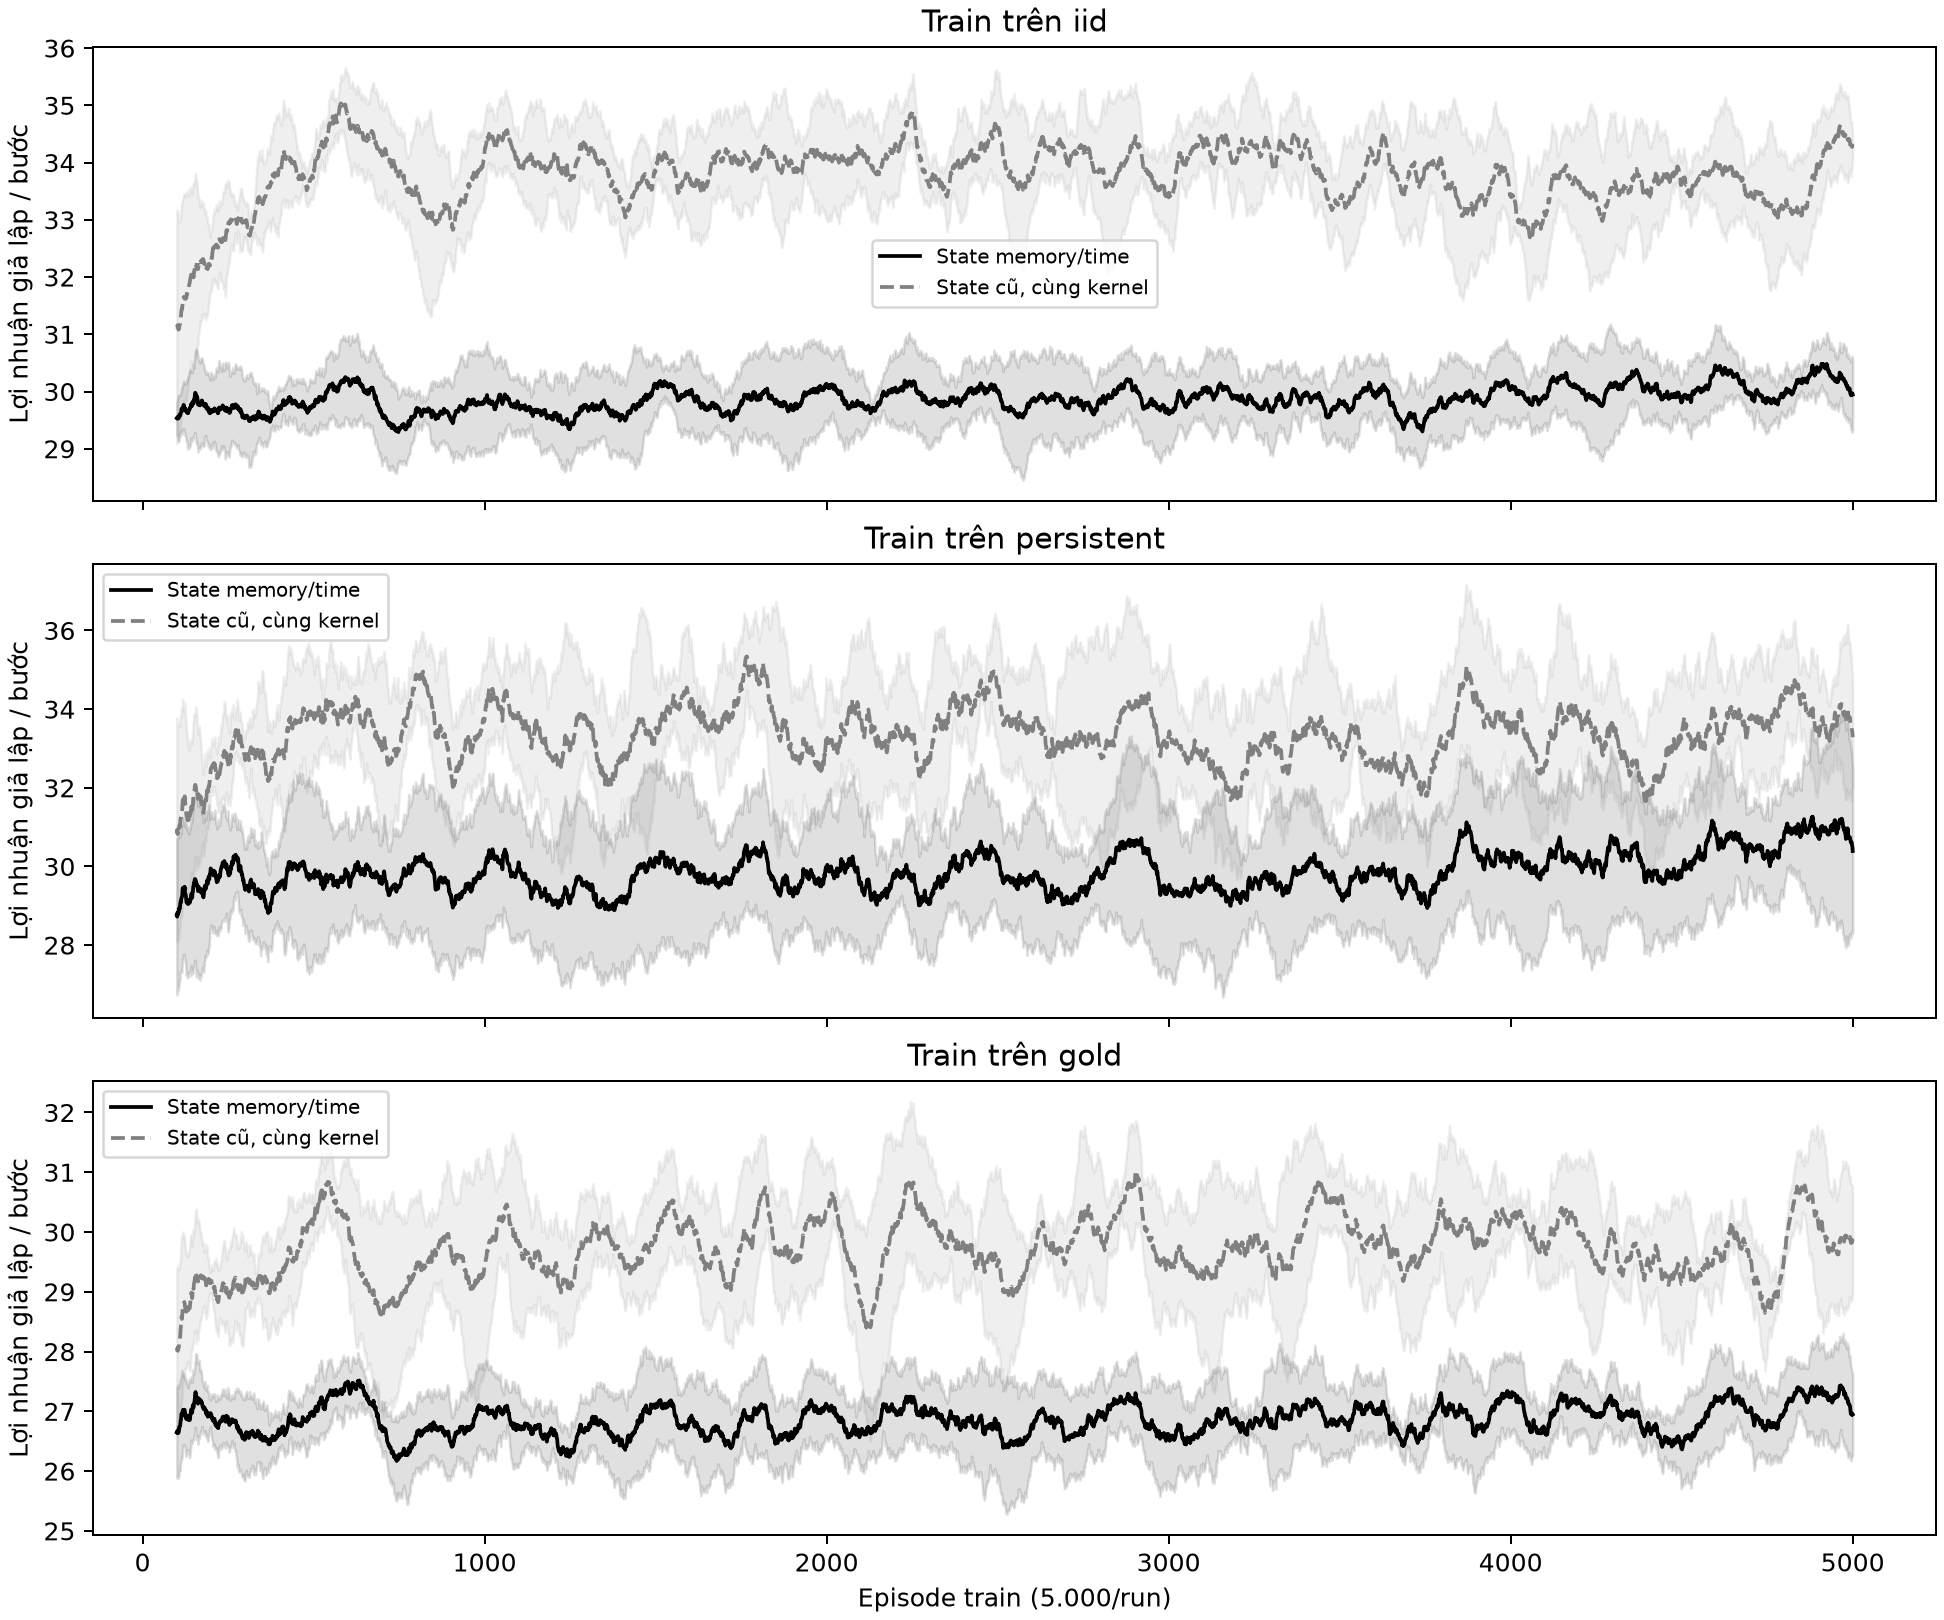

In [40]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F17')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** Ba panel là IID/persistent/Gold; X là episode, Y là profit/bước. Đen liền là state memory/time, xám đứt là state cũ train cùng kernel; mỗi đường là mean MA 100 qua năm seed, dải là sample std tương ứng. Ở cả ba panel, đường memory/time quan sát thấp hơn phần lớn quá trình. Train reward còn exploration và Q thay đổi; không thay nó cho final hoặc suy ra nguyên nhân chỉ từ hình. Nguồn: D7, train_curves.

## Hình F18

Nguồn `artifacts/figures/phase07/augmented_final_profit.png`.

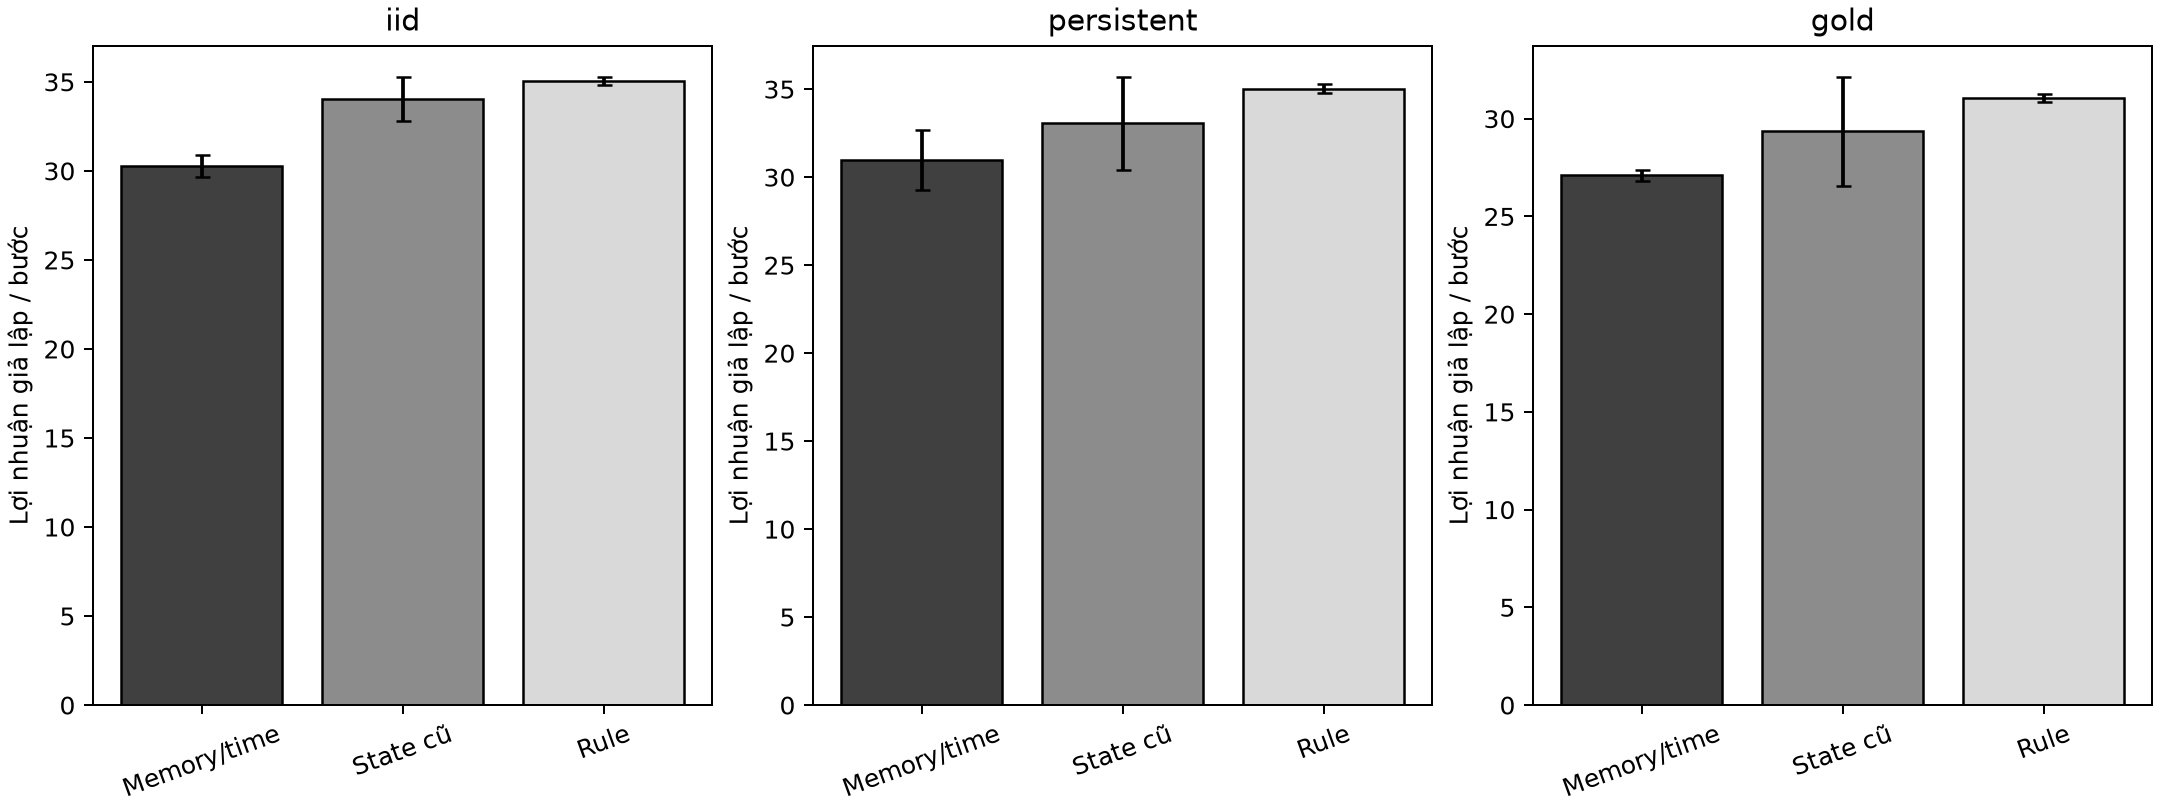

In [41]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F18')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** X là ba policy, Y là profit/bước; cột mean và whisker sample std, n 5 sau gộp vai. IID memory/time đạt 30,27341 so với baseline 34,02786; Gold lần lượt 27,10489/29,35694. Kết quả có std nhỏ hơn không đủ để gọi robust hơn nếu mean thấp hơn. Các panel khác phân phối nên so trong từng kernel là chính. Nguồn: D7, policy_summary.

## Hình F19

Nguồn `artifacts/figures/phase07/augmented_paired_delta.png`.

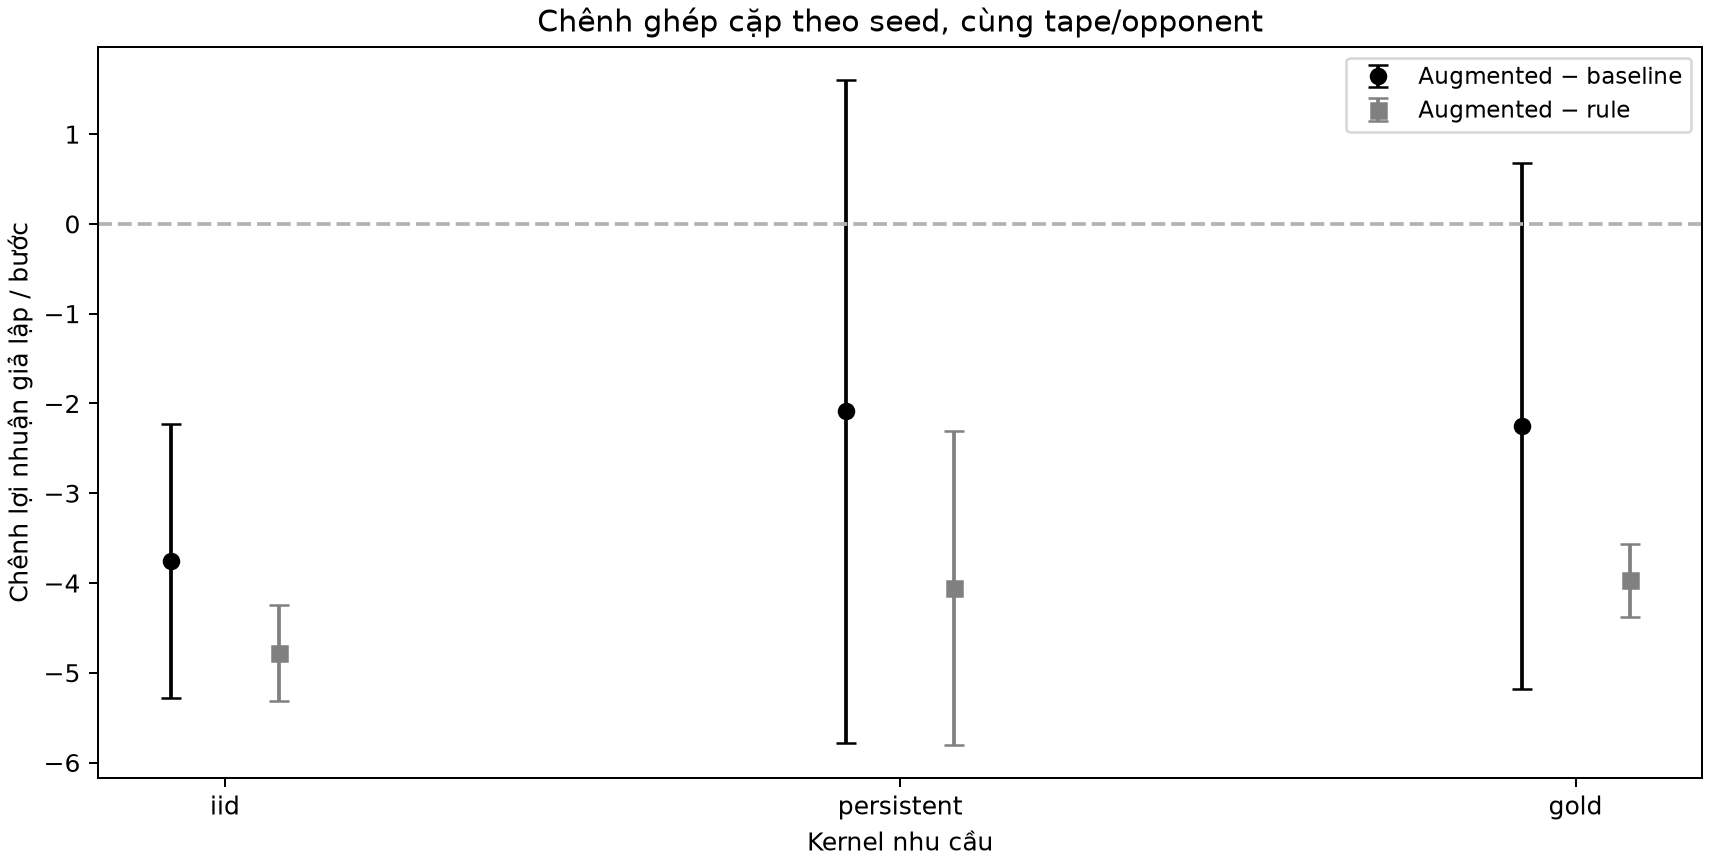

In [42]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F19')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** X là kernel, Y là profit augmented trừ đối chứng/bước. Tròn đen trừ baseline, vuông xám trừ rule; đường đứt 0 là không chênh. Điểm là mean, whisker là sample std của năm delta seed. Mean trừ baseline âm ở cả ba kernel: B11 ghi rõ mức chênh. Whisker qua 0 không phải kiểm định; không loại seed bất lợi hoặc tăng budget sau khi xem score để đảo kết luận. Nguồn: D7, paired_deltas/delta_summary.

## Hình F20

Nguồn `artifacts/figures/phase07/augmented_coverage_cost.png`.

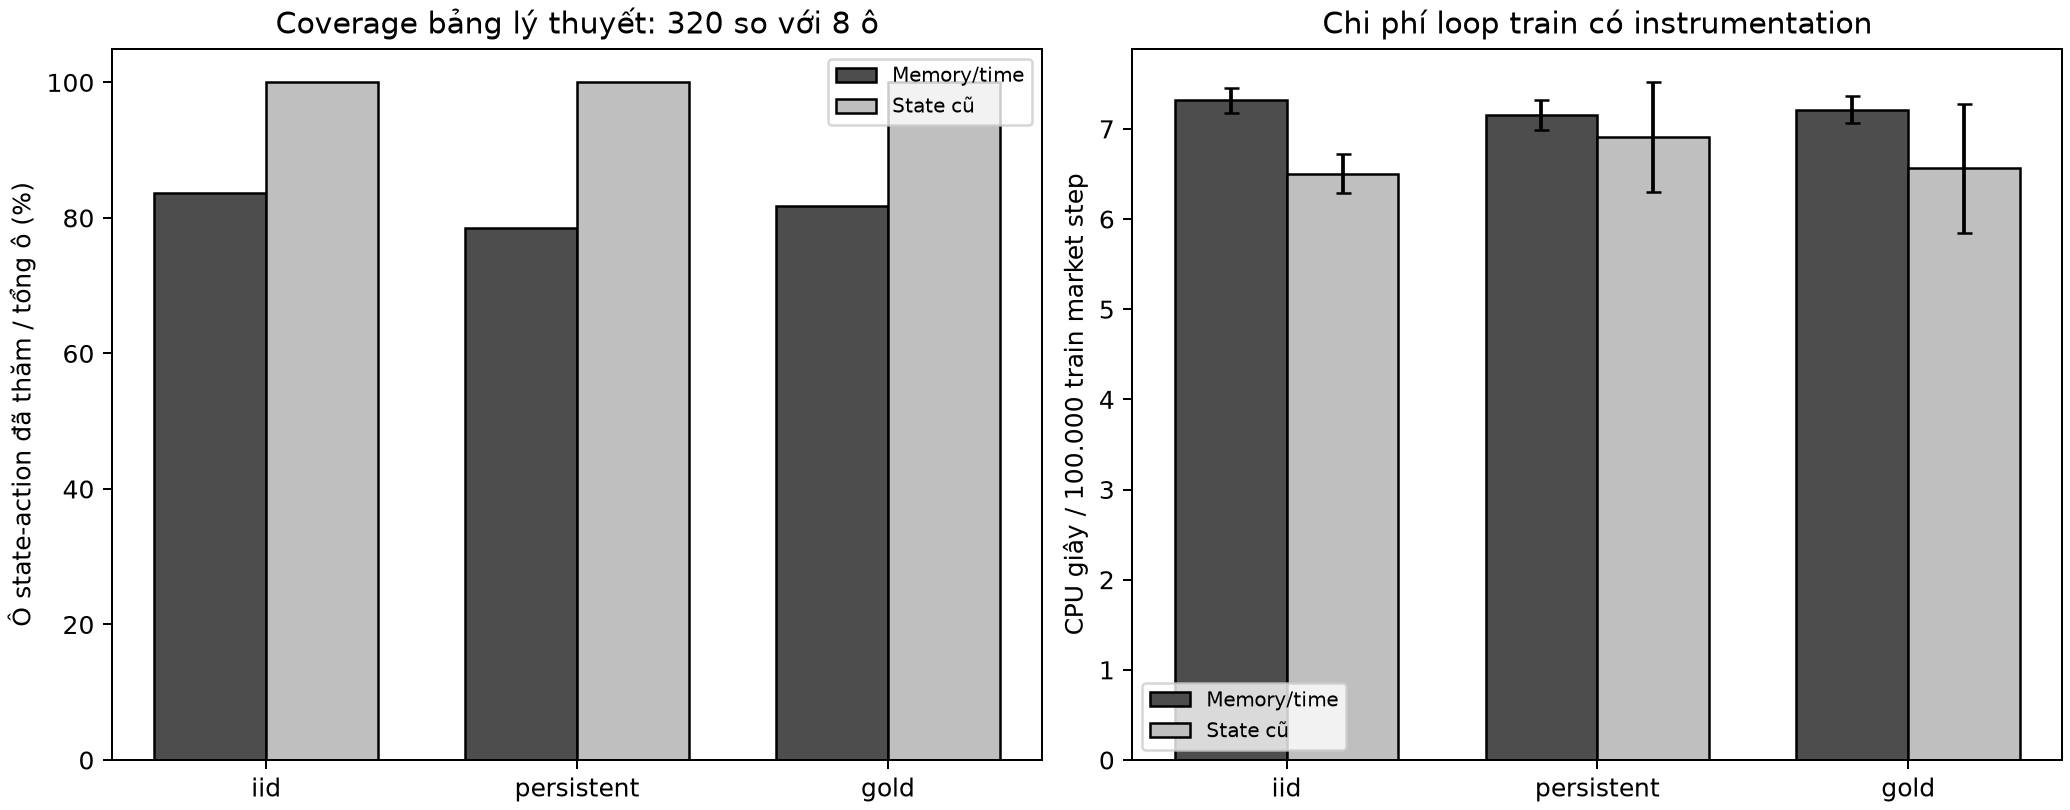

In [43]:
figure = next(f for f in load("report/phase08/figure_catalog.json") if f["id"] == 'F20')
assert sha(BASE / figure["path"]) == figure["sha256"]
display(Image(filename=str(BASE / figure["path"])))

**Giải thích:** X là kernel. Trái: Y là phần trăm ô state–action đã được thăm trên tổng ô lý thuyết; phải: Y là CPUgiây/100.000 train market step. Cột đậm memory/time, nhạt baseline; panel phải có whisker là std qua 5 seed. Agent mới thăm 83,6%/78,4%/ 81,8% của 320 ô trênIID/persistent/Gold, baseline thăm 100% của 8 ô; một số fullstate không đạt được từ reset/horizon nên phần chưa thăm không tự là lỗi. Qpayload float64 tăng 64 → 2.560 byte, không phải peakRAM. CPU loop không gồm checkpointI/O và không phải benchmark hệ thống. Nguồn: D7, cost_coverage.

## 6. Trả lời mười câu hỏi thí nghiệm

### 6.1. Câu 1 — Mô hình tác tử và môi trường

Hai tác tử là hai shop, dùng policy Q-learning và rule trong baseline. Môi trường
chung gồm nhu cầu, lịch sử action, cơ chế xác suất mua và reward. State local cũ
có bốn khả năng từ nhu cầu 0/1 và action trước của đối thủ 0/1; action giữ/giảm giá;
reward là profit. Sau action đồng thời, môi trường sinh sales, lưu action, lấy
nhu cầu mới và trả state/reward tiếp theo. E04 thể hiện đúng thứ tự này.

Theo PEAS, tiêu chí thành công là profit; môi trường là thị trường mô phỏng; bộ
chấp hành là quyết định giữ/giảm giá; thông tin quan sát là nhu cầu/lịch sử. Hai
policy cùng tác động đến xác suất mua và lịch sử của nhau nên đây là MAS qua môi
trường chung, dù không gửi thông điệp [S1, trang PDF 3–7; S6, trang PDF 3–5].

### 6.2. Câu 2 — Quyết định học từ kinh nghiệm và theo luật

| Khía cạnh | Rule-based | Q-learning |
|---|---|---|
| Ra quyết định | Theo nhánh điều kiện do người thiết kế viết | Theo Q đã học và epsilon khi train |
| Kinh nghiệm | Không tự sửa rule sau reward | Reward dùng sửa giá trị action |
| Thích nghi | Cần đổi rule nếu giả định thay đổi | Có thể học lại nhưng không bảo đảm tốt hơn |
| Chi phí | Không train; điều kiện đơn giản | Cần tương tác, lưu Q và kiểm tra nhiều seed |
| Giải thích | Chỉ ra nhánh luật đã dùng | Đọc state/action/Q và kết quả kiểm chứng |

Rule phù hợp khi ràng buộc rõ, cần quyết định nhất quán: ví dụ lọc nhà theo ngân
sách hoặc kiểm hồ sơ đặt lịch tư vấn tiểu đường có đủ trường thông tin. Ví dụ này
không đề xuất chẩn đoán/điều trị từ một nhãn dữ liệu. RL đáng cân nhắc khi quyết
định lặp lại có reward dài hạn và có môi trường thử nghiệm phù hợp, chẳng hạn
chính sách khuyến mãi trong simulator được kiểm chứng trước khi áp dụng.

Trong mẫu đang xét, rule control có mean 35,05235, cao hơn baseline
Q 34,02786; vì vậy khả năng học không đồng nghĩa ưu thế
mặc định. Kết quả này chỉ áp dụng simulator, budget và bộ seed hiện tại (B05,F09).

### 6.3. Câu 3 — Ý nghĩa cập nhật Q và phép tính cụ thể

Công thức cần dùng là:

**Q mới = Q cũ + α × [r + γ × max Q ở state kế − Q cũ].**

Q cũ là đánh giá đang có cho action vừa chọn. r là reward vừa nhận; maxQ ở state
kế là ước lượng tốt nhất cho bước tiếp theo; γ làm giảm trọng số lợi ích xa hơn.
Phần trong ngoặc là chênh giữa target mới và đánh giá cũ; α quyết định sửa bao
nhiêu phần của chênh đó. Ở terminal, target chỉ bằng r vì episode đã kết thúc.

Với số **giả định đề cho**, Q cũ 4, α 0,1, r 6, γ 0,9, maxQ kế 5:

1. Giá trị tương lai có chiết khấu:0,9 × 5=4,5.
2. Target:6+4,5=10,5.
3. Chênh target so Q cũ:10,5−4=6,5.
4. Phần cập nhật:0,1 × 6,5=0,65.
5. Q mới:4+0,65=**4,65**.

Q tăng từ 4 lên 4,65 vì tín hiệu mới tốt hơn đánh giá cũ, nhưng không nhảy thẳng lên
10,5 do alpha chỉ 0,1. Đây là phép tính giả định, không phải một reward hoặc Q đo
từ run. E03 và unit test kiểm đúng phép tính, đồng thời kiểm terminal. Công thức
theo [S1, trang PDF 6,10] và code; survey [S4] được dùng cho phần nền RL.

### 6.4. Câu 4 — Khám phá và khai thác

Epsilon-greedy chọn action ngẫu nhiên với xác suất epsilon; ngoài nhánh đó chọn Q
lớn nhất. Khám phá giúp thử action chưa biết rõ; khai thác dùng kinh nghiệm hiện
tại để thu reward. Khám phá quá nhiều có thể tiếp tục chọn action kém; dừng quá sớm
có thể giữ một đánh giá lệch vì ít được thử lại. Đây là đánh đổi, không phải quy
tắc “epsilon càng cao càng tốt”.

B04,F06–F07 so lịch giảm với epsilon 0,05 và 0,30 cố định. Mean train tương ứng
33,76528,32,89187,
30,92305; final tương ứng
34,02786,33,39952,
32,87013. Các số cuối đều đo với exploration
tắt, không phải vẫn giữ epsilon train. Lịch giảm có mean quan sát cao hơn trong
mẫu này, nhưng độ phân tán seed và n nhỏ hạn chế khẳng định tổng quát. E02 cho
thấy random tie vẫn khác exploration.

### 6.5. Câu 5 — Reward và mục tiêu kinh doanh

Không giảm giá: giá 10−chi phí 5=**5** lợi nhuận/món. Giảm 20%: giá mới 10 × 0,8=8,
lợi nhuận 8−5=**3**/món. Do đó sales tăng chưa chắc profit tổng tăng. Reward trong
bài ưu tiên profit, không đơn thuần số lượng bán [S1, trang PDF 4–5,10].

Nếu reward chỉ đếm sales, learner có thể thích action tăng xác suất mua dù margin
thấp. Nếu thêm tồn kho, phí khuyến mãi hoặc mục tiêu duy trì khách, hành vi tối ưu
cũng có thể khác. Đây là đề xuất thiết kế, không phải các reward đã được triển
khai trong số đo hiện tại. F04/F12 phản ánh action rate thực đo, không chứng minh
mối quan hệ nhân quả giữa giảm giá và profit ngoài mô hình.

### 6.6. Câu 6 — Tính reward trung bình và giới hạn một run

**Reward trung bình mỗi bước = tổng reward / tổng số bước.** B01 có ví dụ REF
train:3.345.548/100.000=33,45548 cho RL và
3.283.930/100.000=32,83930 cho rule. Đây là train
score, không phải kết quả policy cuối.

Với final native REF, tổng Q là 351275, rule
349685, mỗi shop 10000 bước;
mean tương ứng 35,12750/34,96850.
Native chỉ role 0 và RNG gốc, không đưa vào nhóm CONTROLLED n 5 (B06).

Baseline CONTROLLED sau gộp vai có Q mean 34,02786±
1,22178, rule trong cùng trận
33,21968±2,32629. Khi đối chứng
policy rule trước cùng fixed opponent, mean lại là 35,05235. Vì
đối thủ phản ứng với lịch sử, hai phép so sánh không được dùng thay nhau (B05,F10).

Một run chỉ quan sát một chuỗi kinh nghiệm. Nhu cầu, sales, exploration và phá
đồng hạng có thể làm Q cuối khác nhau giữa seed; B06 cho thấy các mean khác nhau
thật. Năm seed và sample std hữu ích hơn một run, nhưng không chứng minh ưu thế
ở thị trường thật hoặc coi mọi timestep là mẫu độc lập.

### 6.7. Câu 7 — Learning rate và độ ổn định

Alpha nhỏ chỉ sửa Q một phần nhỏ sau reward mới; alpha lớn phản ứng mạnh hơn với
quan sát gần nhất. Cập nhật mạnh có thể phản ứng nhanh nhưng cũng nhạy với nhiễu;
alpha nhỏ không tự bảo đảm policy tốt nếu budget hữu hạn và kinh nghiệm khác nhau.

B03,F05 đo α 0,01/0,10/0,50 với các phần khác giữ nguyên. Final mean±std lần lượt
33,90382±2,60833,
34,02786±1,22178,
32,06337±4,25085. Alpha 0,50
có độ phân tán final lớn nhất trong ba nhóm, trong khi std của mean **train** của
nó không lớn như vậy. Hai đại lượng đo khác nhau, nên không dùng curve train
ổn định hơn để kết luận policy cuối ổn định hơn. Kết luận giới hạn ở cấu hình,
budget và seed đã đo; không chọn lại alpha sau final.

### 6.8. Câu 8 — Tương tác và non-stationarity

Action hiện tại của đối thủ ảnh hưởng xác suất mua của shop mình; action trước
ảnh hưởng observation và phản ứng của rule ở bước sau. Khi hai Q-learning cùng
sửa policy, learner gặp một “đối thủ đang thay đổi”: cùng local observation/action
có thể cho kết quả khác do lựa chọn của đối thủ khác, ngoài nhiễu sales vốn có.
Điều này làm việc học khó hơn so với giả định đối thủ cố định.

Một thay đổi thực nghiệm là đóng băng checkpoint rồi đo trước cùng fixed opponent
và tapes. Bài đã thực hiện năm pair seed, hai learner riêng Q/RNG và bốn mốc 0/
1.000/2.500/5.000. B07,F15 có mean 34,48443 ởmốc 1.000 rồi
31,58872 ởmốc 5.000. Không có xu hướng final return tăng đều.
Policy drift và reward dao động chưa tách được riêng tác động nhân quả của đối
thủ đang học, vì alpha, observation và nhiễu vẫn tồn tại. Không chọn mốc tốt nhất
để thay checkpoint cuối hoặc xem 10 learner phụ thuộc là 10 replicate độc lập.

### 6.9. Câu 9 — Hạn chế và sửa môi trường thật sự

Ít nhất năm hạn chế là: conversion chỉ giả định minh họa; nhu cầu IID quá đơn giản;
state cũ thiếu lịch sử của mình/thời gian còn lại; không có inventory hoặc dị biệt
khách; hai shop không chia một lượng sales độc quyền. Gold bổ trợ vẫn là proxy
từ hướng giá, không phải dữ liệu cầu đo được. Các giả định này giới hạn khả năng
suy rộng, kể cả khi mean/std đã được tính đúng.

Sửa đổi đã triển khai là dùng demand Markov: persistent giữ chế độ với xác suất 0,9,
hoặc kernel hiệu chỉnh từ TRAIN Gold. Các phần giá/reward/action/rule/budget giữ
nguyên. E07 tạo các MarketConfig tương ứng; TrainSession cũ dùng đúng kernel đó,
không sửa thuật toán baseline để tạo kết quả thắng:

```python
def markets():
    data = protocol()
    baseline = MarketConfig(**data['market'])
    return {'iid': baseline, 'persistent': replace(baseline, kernel=data['future_variants']['persistent']['kernel']),
        'gold': replace(baseline, kernel=json.loads((BASE/'data/derived/gold_regime_kernel_v1.json').read_text())['kernel'])}
```

Nguồn E07: `phase06.py`, dòng 43–47; SHA256 `6cfec22472893221…` (hash đầy đủ trong code_excerpt_index.json).

Chỉ dùng 560 giá tháng đến 08/2006 để fit kernel (B08,F13). Trên mỗi
kernel mới, đo cả Q IID cũ đóng băng và Q train lại trước cùng fixed rule/tape.
Paired delta retrain−baseline ởpersistent là-1,48087,
ởGold-0,80510 (B09,F16). Trong budget này, train lại không
cải thiện mean. Không từ đó kết luận retrain luôn kém: từng seed khác nhau, chỉ
hai kịch bản sửa môi trường và n 5 nhỏ. Sửa kernel giúp kiểm độ bền trước thay đổi
nhu cầu giả lập, chưa giải quyết toàn bộ các hạn chế trên.

### 6.10. Câu 10 — Thiết kế agent đầy đủ hơn và kiểm chứng

Đề xuất thêm own_previous và remaining_steps vào state, giữ action giữ/giảm giá
và reward profit, dùng Q-learning 320 giá trị. Lý do là hai lịch sử cùng observation
cũ có thể làm rule hiện tại chọn khác nhau; thời gian còn lại cũng quyết định có
nên tính giá trị tương lai hay không. E08 cho thấy thời gian phải giảm đúng 1 và
terminal chỉ nhận reward hiện tại:

```python
def learn(self, state, action, reward, following, terminal):
    index = state_index(state)
    action = binary(action, 'action')
    if not np.isfinite(reward) or bool(terminal)!=(state[3]==1):
        raise ValueError('Invalid reward/terminal time')
    if terminal:
        target = reward
    else:
        following_index = state_index(following)
        if following[3]!=state[3]-1:
            raise ValueError('Remaining time must decrease exactly1')
        target = reward+self.config.gamma*float(self.q[following_index].max())
    key = (*index, action)
    self.q[key] += self.config.alpha*(target-self.q[key])
    if not np.isfinite(self.q[key]):
        raise ValueError('Nonfinite augmented Q update')
```

Nguồn E08: `code/augmented.py`, dòng 73–88; SHA256 `3638a130760b2bc3…` (hash đầy đủ trong code_excerpt_index.json).

Để kiểm robust, train trên ba kernel với cùng 5 seed và 5.000 × 20 budget, sau đó đo Q
đóng băng 500 episode/vai trước cùng fixed rule/tapes. So với baseline **đã train
trên cùng kernel** và rule; đọc paired return, std giữa seed, action rate và cost.
Các đối chứng cũ được reuse output, không forward lại để thay điểm (B10–B12,F17–F20).

Trong thực nghiệm, augmented−baseline mean là-3,75445
trênIID,-2,08854 trênpersistent và
-2,25205 trênGold. Mean đều thấp hơn đối chứng nên
chưa đạt mục tiêu cải thiện robust. State biểu diễn đầy đủ hơn là một lý do thiết
kế, không phải bảo đảm học tốt hơn dưới budget cố định. Bảng lớn hơn/cùng số tương
tác là một giả thuyết cần khảo sát thêm, chưa được chứng minh là nguyên nhân duy nhất.

Oracle tính lùi bằng simulator đã biết chỉ dùng đối chiếu kỳ vọng (B12). Nó không
cấp action/Q tối ưu làm nhãn hoặc khởi tạo learner; không gọi là tác tử model-free
đã học. Không dùng kết quả âm để âm thầm tăng budget hoặc tune lại. Một nghiên cứu
tiếp theo có thể đăng ký trước budget/ablation mới, rồi thu bộ đánh giá mới để
kiểm giả thuyết, thay vì sử dụng lại các score cuối hiện tại.



In [44]:
after = {row["path"]: sha(BASE / row["path"]) for row in inputs}
assert before == after
print("PASS: all", len(after), "input files unchanged. Training steps=0; final forwards=0.")

PASS: all 70 input files unchanged. Training steps=0; final forwards=0.
